# Изучение закономерностей, определяющих успешность игр

**План проекта**

1. [Изучени еобщей информации](#010)
2. [Подготовка данных](#020)
3. [Проведение исследовательского анализа данных](#030)
4. [Составление портрета пользователя каждого региона](#040)
5. [Проверка гипотез](#050)
6. [Выводы](#060)


**Данные**
В наличии имелся отдин датасет со следующими данными:
- название игры
- платформа
- год выпуска
- жанр игры
- продажи в Северной Америке (миллионы проданных копий)
- продажи в Европе (миллионы проданных копий)
- продажи в Японии (миллионы проданных копий)
- продажи в других странах (миллионы проданных копий)
- оценка критиков (максимум 100)
- оценка пользователей (максимум 10)
- рейтинг от организации ESRB (англ. Entertainment Software Rating Board). Эта ассоциация определяет рейтинг компьютерных игр и присваивает им подходящую возрастную категорию.

In [1]:
import pandas as pd
import datetime
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
import calendar
from scipy import stats as st
from math import factorial
import plotly.express as px
pd.set_option('display.max_columns', 100)# можно не 100, а none
%matplotlib inline
#pd.options.display.float_format = '{:,.2f}'.format

# 1. Изучени еобщей информации<a id='010'>

In [2]:
games = pd.read_csv("/datasets/games.csv")
print(games.shape)
games.info()
games.head()
#games.to_csv('games.csv', index = False)

(16715, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
Name               16713 non-null object
Platform           16715 non-null object
Year_of_Release    16446 non-null float64
Genre              16713 non-null object
NA_sales           16715 non-null float64
EU_sales           16715 non-null float64
JP_sales           16715 non-null float64
Other_sales        16715 non-null float64
Critic_Score       8137 non-null float64
User_Score         10014 non-null object
Rating             9949 non-null object
dtypes: float64(6), object(5)
memory usage: 1.4+ MB


,Name,Platform,Year_of_Release,Genre,NA_sales,EU_sales,JP_sales,Other_sales,Critic_Score,User_Score,Rating
0,Wii Sports,Wii,2006.0,Sports,41.36,28.96,3.77,8.45,76.0,8,E
1,Super Mario Bros.,NES,1985.0,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E
3,Wii Sports Resort,Wii,2009.0,Sports,15.61,10.93,3.28,2.95,80.0,8,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN


Таблица содержит в себе  исторические данные о продажах игр. Она содержит 16715 строк и 11 столбцов. Всртечается 2 типа данных: вещественные числа (6 столбцов) и строки (5 столбцов). Видим наличие пропусков в 6 столбцах. Значиельные пропуски присутсвуют в столбцах: Critic_Score, Rating, User_Score.

# 2. Подготовка данных<a id='020'>

В рамаках подготовки данных нам необходимо:
* Заменить названия столбцов (приведите к нижнему регистру);
* Преобразовать данные в нужные типы. Описать, в каких столбцах заменили тип данных и почему;
* Обработать пропуски при необходимости:
  - Объяснить, почему заполнили пропуски определённым образом или почему не стали это делать;
  - Описать причины, которые могли привести к пропускам;
  - Обратить внимание на аббревиатуру 'tbd' в столбцах с рейтингом. Отдельно разобрать это значение и описать, как его     обработать;
* Посчитайте суммарные продажи во всех регионах и запишите их в отдельный столбец.


### Приведем названия столбцов к нижнему регистру

In [3]:
games.columns = games.columns.str.lower()
games.columns

Index(['name', 'platform', 'year_of_release', 'genre', 'na_sales', 'eu_sales',
       'jp_sales', 'other_sales', 'critic_score', 'user_score', 'rating'],
      dtype='object')

Все Ок!

### Преобразуем данные в нужные типы. Опишем, в каких столбцах заменили тип данных и почему;

* Name — тип правильный - строка
* Platform — тип правильный - строка
* Year_of_Release — год выпуска - это целое число, переведем его в int. Но поскольку там есть пропуски, то сделаем это после избавления от пропусков
* Genre — тип правильный - строка
* NA_sales — тип правильный - десятичная дробь с плавающей точкой
* EU_sales — тип правильный - десятичная дробь с плавающей точкой
* JP_sales — тип правильный - десятичная дробь с плавающей точкой
* Other_sales — тип правильный - десятичная дробь с плавающей точкой
* Critic_Score — оценка критиков выражается четым числом, переведем его в int.
* User_Score — оценка пользователей измеряется десятичной дробью, поэтому ее нужно перивести в десятичную дробь с  
  плавающей точкой. Но там попадаются значения 'tbd' - "Подлежит определению", поэтому замениv тип послt проработки этого   столбца
* Rating — рейтинг от организации ESRB (англ. Entertainment Software Rating Board) - этот рейтинг выражается буквенно- 
  цифровым способом. Поэтому имеет правильный тип - строка
  
Итог: нам нужно заметить тип в следующих столбцах:
* Year_of_Release
* Critic_Score
* User_Score

Вернемся к этой задаче после обработки пропускоы по этим столбцам.

### Изменим year_of_release на int

In [4]:
games["year_of_release"] = games["year_of_release"].astype('Int64')

In [5]:
games.head(1)

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating
0,Wii Sports,Wii,2006,Sports,41.36,28.96,3.77,8.45,76.0,8,E


Замены прошли успешно

### Изменим critic_score на int

In [6]:
games["critic_score"] = games["critic_score"].astype('Int64')

In [7]:
games.head(1)

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating
0,Wii Sports,Wii,2006,Sports,41.36,28.96,3.77,8.45,76,8,E


Изменения прошли успешно

### Изменим user_score на int

Замну нужно проводить с одновременной заменой tbd на NaN, поскольку tbd в данном случае - это незаполненный рейтинг, т.е. пропуск.

In [8]:
games['user_score'] = pd.to_numeric(games['user_score'], errors='coerce')

Проверим теперь тип данных целиком

In [9]:
games.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
name               16713 non-null object
platform           16715 non-null object
year_of_release    16446 non-null Int64
genre              16713 non-null object
na_sales           16715 non-null float64
eu_sales           16715 non-null float64
jp_sales           16715 non-null float64
other_sales        16715 non-null float64
critic_score       8137 non-null Int64
user_score         7590 non-null float64
rating             9949 non-null object
dtypes: Int64(2), float64(5), object(4)
memory usage: 1.4+ MB


Видим, что теперь данные имеют корректный тип

### Обработаем пропуски

### Определим % пропущенных значений в столбцах

In [10]:
(games.isnull().sum()/games.shape[0]*100).sort_values(ascending = False)

user_score         54.591684
critic_score       51.319174
rating             40.478612
year_of_release     1.609333
genre               0.011965
name                0.011965
other_sales         0.000000
jp_sales            0.000000
eu_sales            0.000000
na_sales            0.000000
platform            0.000000
dtype: float64

#### Обработаем пропуска в user_score

В данно столбце содержится более 54% пропусков. Посмотрим, с чем коррелируют данные из столбца user_score

In [11]:
games.corr()["user_score"].sort_values(ascending = False)

user_score         1.000000
critic_score       0.580878
jp_sales           0.125598
na_sales           0.086200
other_sales        0.057119
eu_sales           0.055337
year_of_release   -0.267851
Name: user_score, dtype: float64

Мы видим, что у user_score достаточнно высокая корреляция с critic_score. Но в critic_score также присутсвует болеее 51% пропусков, поэтому восстановить по этому столбцу все данные в user_score не получиться. Попытаемся сначало сделать срез по строкам, в которых есть все данные по столбцу critic_score и уже потом по этому фрагменту таблицы восстановим часть данных в столбце user_score.

In [12]:
games_critic_score_clan = games.dropna(axis='index', how='any', subset=['critic_score'])

In [13]:
games_critic_score_clan

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating
0,Wii Sports,Wii,2006,Sports,41.36,28.96,3.77,8.45,76,8.0,E
2,Mario Kart Wii,Wii,2008,Racing,15.68,12.76,3.79,3.29,82,8.3,E
3,Wii Sports Resort,Wii,2009,Sports,15.61,10.93,3.28,2.95,80,8.0,E
6,New Super Mario Bros.,DS,2006,Platform,11.28,9.14,6.50,2.88,89,8.5,E
7,Wii Play,Wii,2006,Misc,13.96,9.18,2.93,2.84,58,6.6,E
...,...,...,...,...,...,...,...,...,...,...,...
16696,Breach,PC,2011,Shooter,0.01,0.00,0.00,0.00,61,5.8,T
16697,Bust-A-Move 3000,GC,2003,Puzzle,0.01,0.00,0.00,0.00,53,NaN,E
16698,Mega Brain Boost,DS,2008,Puzzle,0.01,0.00,0.00,0.00,48,NaN,E
16702,STORM: Frontline Nation,PC,2011,Strategy,0.00,0.01,0.00,0.00,60,7.2,E10+


In [14]:
(games_critic_score_clan.isna().sum()/games_critic_score_clan.shape[0]*100).sort_values(ascending = False)

user_score         13.764287
year_of_release     1.892589
rating              1.020032
critic_score        0.000000
other_sales         0.000000
jp_sales            0.000000
eu_sales            0.000000
na_sales            0.000000
genre               0.000000
platform            0.000000
name                0.000000
dtype: float64

Имеем часть фрейма games, в котором нет пропусков в critic_score. В данном фрейме 13% данных в user_score пропущены. Посморим на оставшиея пропуска в games_critic_score_clan

In [15]:
games_critic_score_clan[games_critic_score_clan.user_score.isna()]

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating
182,Tomb Raider II,PS,1997,Action,2.30,2.46,0.2,0.28,85,NaN,T
301,Namco Museum: 50th Anniversary,PS2,2005,Misc,2.08,1.35,0.0,0.54,61,NaN,E10+
440,Need for Speed III: Hot Pursuit,PS,1998,Racing,2.14,0.86,0.0,0.13,88,NaN,E
637,Riven: The Sequel to Myst,PC,1997,Adventure,1.52,0.82,0.0,0.10,83,NaN,E
645,uDraw Studio,Wii,2010,Misc,1.65,0.57,0.0,0.20,71,NaN,E
...,...,...,...,...,...,...,...,...,...,...,...
16577,Space Raiders,GC,2003,Shooter,0.01,0.00,0.0,0.00,40,NaN,T
16669,Super Robot Taisen: Original Generation,GBA,2002,Role-Playing,0.01,0.00,0.0,0.00,72,NaN,T
16695,Planet Monsters,GBA,2001,Action,0.01,0.00,0.0,0.00,67,NaN,E
16697,Bust-A-Move 3000,GC,2003,Puzzle,0.01,0.00,0.0,0.00,53,NaN,E


1120 пропусков. Попытатаемся восстановить их по данным из critic_score, посколку у данных столбцов высокая корреляция. 

In [16]:
games_critic_score_clan['user_score'] = (games_critic_score_clan.groupby('critic_score')['user_score'].transform(lambda x: x.fillna(x.mean())))

/opt/conda/lib/python3.7/site-packages/ipykernel_launcher.py:1: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



Посморим, все ли замены прошли

In [17]:
games_critic_score_clan[games_critic_score_clan.user_score.isna()]

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating


Замены прошли успешно.

Теперь нам нужно заменить NaN в строках таблицы games, для которых мы получили значения выше. Для этого объединим таблцы games и games_critic_score_clan и затем произведем замены. 

In [18]:
games_general = games.merge(games_critic_score_clan, on=["name", "platform", "year_of_release"], how='outer')# объединяем таблицы

In [19]:
games_general["user_score_x"].fillna(games_general["user_score_y"], inplace = True)# проводим замены

Посмотрим, что получилось

In [20]:
games_general.head(1)

,name,platform,year_of_release,genre_x,na_sales_x,eu_sales_x,jp_sales_x,other_sales_x,critic_score_x,user_score_x,rating_x,genre_y,na_sales_y,eu_sales_y,jp_sales_y,other_sales_y,critic_score_y,user_score_y,rating_y
0,Wii Sports,Wii,2006,Sports,41.36,28.96,3.77,8.45,76,8.0,E,Sports,41.36,28.96,3.77,8.45,76,8.0,E


In [21]:
games_general.columns[11:19]

Index(['genre_y', 'na_sales_y', 'eu_sales_y', 'jp_sales_y', 'other_sales_y',
       'critic_score_y', 'user_score_y', 'rating_y'],
      dtype='object')

Удалим лишние столбцы оставшиеся от таблицы games_critic_score_clan

In [22]:
games_general = games_general.drop(['genre_y', 'na_sales_y', 'eu_sales_y', 'jp_sales_y', 'other_sales_y',
       'critic_score_y', 'user_score_y', 'rating_y'], axis=1)

In [23]:
games_general.head(1)

,name,platform,year_of_release,genre_x,na_sales_x,eu_sales_x,jp_sales_x,other_sales_x,critic_score_x,user_score_x,rating_x
0,Wii Sports,Wii,2006,Sports,41.36,28.96,3.77,8.45,76,8.0,E


Проверим, насколько хорошо нам удалось избавиться от пропусков

In [24]:
(games.isnull().sum()/games.shape[0]*100).sort_values(ascending = False)# фрейм до удаления пропусков

user_score         54.591684
critic_score       51.319174
rating             40.478612
year_of_release     1.609333
genre               0.011965
name                0.011965
other_sales         0.000000
jp_sales            0.000000
eu_sales            0.000000
na_sales            0.000000
platform            0.000000
dtype: float64

In [25]:
(games_general.isnull().sum()/games_general.shape[0]*100).sort_values(ascending = False)

critic_score_x     51.313035
user_score_x       47.885386
rating_x           40.473769
year_of_release     1.609140
genre_x             0.011964
name                0.011964
other_sales_x       0.000000
jp_sales_x          0.000000
eu_sales_x          0.000000
na_sales_x          0.000000
platform            0.000000
dtype: float64

Мы сократили количество пропусков с 54% до 47% - это те самые 1120 пропусков. Для повышения достоверности выводов это конечно скромный вариант, но для учебных целей сделать было полезно.

#### Обработаем аналогичным образом пропуска в critic_score

В данном столбце содержится более 51% пропусков.

In [26]:
games_user_score_clean = games_general.dropna(axis='index', how='any', subset=['user_score_x'])

In [27]:
games_user_score_clean

,name,platform,year_of_release,genre_x,na_sales_x,eu_sales_x,jp_sales_x,other_sales_x,critic_score_x,user_score_x,rating_x
0,Wii Sports,Wii,2006,Sports,41.36,28.96,3.77,8.45,76,8.000000,E
2,Mario Kart Wii,Wii,2008,Racing,15.68,12.76,3.79,3.29,82,8.300000,E
3,Wii Sports Resort,Wii,2009,Sports,15.61,10.93,3.28,2.95,80,8.000000,E
6,New Super Mario Bros.,DS,2006,Platform,11.28,9.14,6.50,2.88,89,8.500000,E
7,Wii Play,Wii,2006,Misc,13.96,9.18,2.93,2.84,58,6.600000,E
...,...,...,...,...,...,...,...,...,...,...,...
16698,Breach,PC,2011,Shooter,0.01,0.00,0.00,0.00,61,5.800000,T
16699,Bust-A-Move 3000,GC,2003,Puzzle,0.01,0.00,0.00,0.00,53,6.411765,E
16700,Mega Brain Boost,DS,2008,Puzzle,0.01,0.00,0.00,0.00,48,5.661111,E
16704,STORM: Frontline Nation,PC,2011,Strategy,0.00,0.01,0.00,0.00,60,7.200000,E10+


In [28]:
(games_user_score_clean.isna().sum()/games_user_score_clean.shape[0]*100).sort_values(ascending = False)

critic_score_x     6.577135
year_of_release    1.813590
rating_x           1.136364
user_score_x       0.000000
other_sales_x      0.000000
jp_sales_x         0.000000
eu_sales_x         0.000000
na_sales_x         0.000000
genre_x            0.000000
platform           0.000000
name               0.000000
dtype: float64

Имеем часть фрейма games, в котором нет пропусков в user_score. В данном фрейме 6,6% данных в critic_score пропущены. Посморим на оставшиея пропуска в games_user_score_clean

In [29]:
games_user_score_clean[games_user_score_clean.critic_score_x.isna()]

,name,platform,year_of_release,genre_x,na_sales_x,eu_sales_x,jp_sales_x,other_sales_x,critic_score_x,user_score_x,rating_x
255,Call of Duty: Advanced Warfare,PS3,2014,Shooter,1.56,1.93,0.19,0.68,NaN,4.8,M
263,Call of Duty: Advanced Warfare,X360,2014,Shooter,2.77,1.11,0.00,0.40,NaN,4.9,M
264,FIFA 15,PS3,2014,Sports,0.58,3.02,0.04,0.64,NaN,4.5,E
291,World Soccer Winning Eleven 9,PS2,2005,Sports,0.12,2.26,0.90,0.77,NaN,8.2,E
359,Just Dance 2014,Wii,2013,Misc,1.88,1.39,0.00,0.31,NaN,6.2,E10+
...,...,...,...,...,...,...,...,...,...,...,...
16638,Deal or No Deal,PC,2006,Misc,0.00,0.01,0.00,0.00,NaN,7.5,E
16645,Rugby Challenge 3,XOne,2016,Sports,0.00,0.01,0.00,0.00,NaN,6.6,E
16656,Ben 10 Omniverse 2,X360,2013,Action,0.00,0.01,0.00,0.00,NaN,5.1,E10+
16663,Bookworm Deluxe,PC,2006,Puzzle,0.01,0.00,0.00,0.00,NaN,8.0,E


573 пропуска. Попытатаемся восстановить их по данным из user_score, посколку у данных столбцов высокая корреляция. Для корректной работы периведем 'critic_score_x' во float   

In [30]:
games_user_score_clean['critic_score_x'] = games_user_score_clean['critic_score_x'].astype('float64')

/opt/conda/lib/python3.7/site-packages/ipykernel_launcher.py:1: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



In [31]:
games_user_score_clean['critic_score_x'] = (games_user_score_clean.groupby('user_score_x')['critic_score_x'].transform(lambda x: x.fillna(x.mean())))

/opt/conda/lib/python3.7/site-packages/ipykernel_launcher.py:1: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



In [32]:
games_user_score_clean

,name,platform,year_of_release,genre_x,na_sales_x,eu_sales_x,jp_sales_x,other_sales_x,critic_score_x,user_score_x,rating_x
0,Wii Sports,Wii,2006,Sports,41.36,28.96,3.77,8.45,76.0,8.000000,E
2,Mario Kart Wii,Wii,2008,Racing,15.68,12.76,3.79,3.29,82.0,8.300000,E
3,Wii Sports Resort,Wii,2009,Sports,15.61,10.93,3.28,2.95,80.0,8.000000,E
6,New Super Mario Bros.,DS,2006,Platform,11.28,9.14,6.50,2.88,89.0,8.500000,E
7,Wii Play,Wii,2006,Misc,13.96,9.18,2.93,2.84,58.0,6.600000,E
...,...,...,...,...,...,...,...,...,...,...,...
16698,Breach,PC,2011,Shooter,0.01,0.00,0.00,0.00,61.0,5.800000,T
16699,Bust-A-Move 3000,GC,2003,Puzzle,0.01,0.00,0.00,0.00,53.0,6.411765,E
16700,Mega Brain Boost,DS,2008,Puzzle,0.01,0.00,0.00,0.00,48.0,5.661111,E
16704,STORM: Frontline Nation,PC,2011,Strategy,0.00,0.01,0.00,0.00,60.0,7.200000,E10+


Теперь нам нужно заменить NaN в строках таблицы games_general, для которых мы получили значения выше. Для этого объединим таблцы games_general и games_user_score_clean и затем произведем замены. 

In [33]:
games_general

,name,platform,year_of_release,genre_x,na_sales_x,eu_sales_x,jp_sales_x,other_sales_x,critic_score_x,user_score_x,rating_x
0,Wii Sports,Wii,2006,Sports,41.36,28.96,3.77,8.45,76,8.0,E
1,Super Mario Bros.,NES,1985,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008,Racing,15.68,12.76,3.79,3.29,82,8.3,E
3,Wii Sports Resort,Wii,2009,Sports,15.61,10.93,3.28,2.95,80,8.0,E
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
16712,Samurai Warriors: Sanada Maru,PS3,2016,Action,0.00,0.00,0.01,0.00,NaN,NaN,NaN
16713,LMA Manager 2007,X360,2006,Sports,0.00,0.01,0.00,0.00,NaN,NaN,NaN
16714,Haitaka no Psychedelica,PSV,2016,Adventure,0.00,0.00,0.01,0.00,NaN,NaN,NaN
16715,Spirits & Spells,GBA,2003,Platform,0.01,0.00,0.00,0.00,NaN,NaN,NaN


In [34]:
games_general = games_general.merge(games_user_score_clean, on=["name", "platform", "year_of_release"], how='outer')# объединяем таблицы

In [35]:
games_general

,name,platform,year_of_release,genre_x_x,na_sales_x_x,eu_sales_x_x,jp_sales_x_x,other_sales_x_x,critic_score_x_x,user_score_x_x,rating_x_x,genre_x_y,na_sales_x_y,eu_sales_x_y,jp_sales_x_y,other_sales_x_y,critic_score_x_y,user_score_x_y,rating_x_y
0,Wii Sports,Wii,2006,Sports,41.36,28.96,3.77,8.45,76,8.0,E,Sports,41.36,28.96,3.77,8.45,76.0,8.0,E
1,Super Mario Bros.,NES,1985,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008,Racing,15.68,12.76,3.79,3.29,82,8.3,E,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E
3,Wii Sports Resort,Wii,2009,Sports,15.61,10.93,3.28,2.95,80,8.0,E,Sports,15.61,10.93,3.28,2.95,80.0,8.0,E
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16724,Samurai Warriors: Sanada Maru,PS3,2016,Action,0.00,0.00,0.01,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
16725,LMA Manager 2007,X360,2006,Sports,0.00,0.01,0.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
16726,Haitaka no Psychedelica,PSV,2016,Adventure,0.00,0.00,0.01,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
16727,Spirits & Spells,GBA,2003,Platform,0.01,0.00,0.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Приведем данные в столбцах к одному типу и проведем замены

In [36]:
games_general.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 16729 entries, 0 to 16728
Data columns (total 19 columns):
name                16727 non-null object
platform            16729 non-null object
year_of_release     16460 non-null Int64
genre_x_x           16727 non-null object
na_sales_x_x        16729 non-null float64
eu_sales_x_x        16729 non-null float64
jp_sales_x_x        16729 non-null float64
other_sales_x_x     16729 non-null float64
critic_score_x_x    8151 non-null Int64
user_score_x_x      8724 non-null float64
rating_x_x          9963 non-null object
genre_x_y           8724 non-null object
na_sales_x_y        8724 non-null float64
eu_sales_x_y        8724 non-null float64
jp_sales_x_y        8724 non-null float64
other_sales_x_y     8724 non-null float64
critic_score_x_y    8713 non-null float64
user_score_x_y      8724 non-null float64
rating_x_y          8625 non-null object
dtypes: Int64(2), float64(11), object(6)
memory usage: 2.6+ MB


In [37]:
games_general['critic_score_x_x'] = games_general['critic_score_x_x'].astype('float64')

In [38]:
games_general["critic_score_x_x"].fillna(games_general["critic_score_x_y"], inplace = True)# проводим замены

Посмотрим, что получилось

In [39]:
games_general.head(1)

,name,platform,year_of_release,genre_x_x,na_sales_x_x,eu_sales_x_x,jp_sales_x_x,other_sales_x_x,critic_score_x_x,user_score_x_x,rating_x_x,genre_x_y,na_sales_x_y,eu_sales_x_y,jp_sales_x_y,other_sales_x_y,critic_score_x_y,user_score_x_y,rating_x_y
0,Wii Sports,Wii,2006,Sports,41.36,28.96,3.77,8.45,76.0,8.0,E,Sports,41.36,28.96,3.77,8.45,76.0,8.0,E


Удалим лишние столбцы оставшиеся от таблицы games_user_score_clean

In [40]:
games_general = games_general.drop(['genre_x_y', 'na_sales_x_y', 'eu_sales_x_y', 'jp_sales_x_y', 'other_sales_x_y', 'critic_score_x_y', 'user_score_x_y', 'rating_x_y'], axis=1)

In [41]:
games_general.head(1)

,name,platform,year_of_release,genre_x_x,na_sales_x_x,eu_sales_x_x,jp_sales_x_x,other_sales_x_x,critic_score_x_x,user_score_x_x,rating_x_x
0,Wii Sports,Wii,2006,Sports,41.36,28.96,3.77,8.45,76.0,8.0,E


Проверим, насколько хорошо нам удалось избавиться от пропусков

In [42]:
(games_general.isnull().sum()/games_general.shape[0]*100).sort_values(ascending = False)# фрейм до удаления пропусков

critic_score_x_x    47.916791
user_score_x_x      47.851037
rating_x_x          40.444737
year_of_release      1.607986
genre_x_x            0.011955
name                 0.011955
other_sales_x_x      0.000000
jp_sales_x_x         0.000000
eu_sales_x_x         0.000000
na_sales_x_x         0.000000
platform             0.000000
dtype: float64

Мы сократили количество пропусков с 51.3% до 47,9% - это те самые 573 пропускf. Для повышения достоверности выводов это конечно скромный вариант, но для учебных целей сделать было полезно.

Заменим названия таблицы и столбцов на исходные

In [43]:
games = games_general

In [44]:
games.columns = (['name', 'platform', 'year_of_release', 'genre', 'na_sales', 'eu_sales',
       'jp_sales', 'other_sales', 'critic_score', 'user_score', 'rating'])

Проверим, как все прошло

In [45]:
games.head(1)

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating
0,Wii Sports,Wii,2006,Sports,41.36,28.96,3.77,8.45,76.0,8.0,E


Все Ок! Продолжим дальше

Отзывы в рейтингаз ни с чем не коррелируют и не могут коррелировать, поскольку это строка. Из восстановить не получиться.

Причина большого количества пропусков в отзывах и рейтингах очевидна. Их начали писать с начала 2000-х годов, с появлнием интернета в широких массах. Это демонстрирует следующий график.

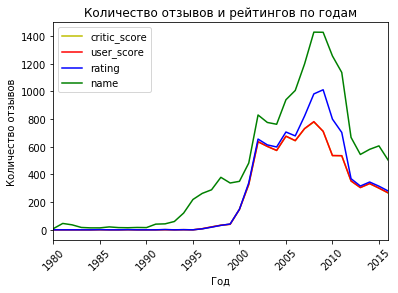

In [46]:
games.groupby("year_of_release")["critic_score"].count().plot(rot = 45, color = "y")
games.groupby("year_of_release")["user_score"].count().plot(rot = 45, color = "r")
games.groupby("year_of_release")["rating"].count().plot(rot = 45, color = "b")
games.groupby("year_of_release")["name"].count().plot(rot = 45, color = "g")
plt.ylabel('Количество отзывов')
plt.xlabel('Год')
plt.legend(prop={'size': 10})
plt.title('Количество отзывов и рейтингов по годам', size=12)
plt.show()

Снижение количства отзывов после 2008 года связано со снижением продаж игр.

#### Удалене пропусков в столбцах year_of_release, genre, name

В данных столбцаз пропусков немного и строки с этими столбцами можно просто удалить

In [47]:
games = games.dropna(axis='index', how='any', subset=['year_of_release']).reset_index(drop=True)
games = games.dropna(axis='index', how='any', subset=['genre']).reset_index(drop=True)
games = games.dropna(axis='index', how='any', subset=['name']).reset_index(drop=True)

Проверим как прошли замены

In [48]:
(games.isnull().sum()/games.shape[0]*100).sort_values(ascending = False)

critic_score       48.019200
user_score         47.952364
rating             40.563860
other_sales         0.000000
jp_sales            0.000000
eu_sales            0.000000
na_sales            0.000000
genre               0.000000
year_of_release     0.000000
platform            0.000000
name                0.000000
dtype: float64

Все Ок! Идем дальше.

### Посчитаем суммарные продажи во всех регионах и запишем их в отдельный столбец.

In [49]:
games

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating
0,Wii Sports,Wii,2006,Sports,41.36,28.96,3.77,8.45,76.0,8.0,E
1,Super Mario Bros.,NES,1985,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E
3,Wii Sports Resort,Wii,2009,Sports,15.61,10.93,3.28,2.95,80.0,8.0,E
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
16453,Samurai Warriors: Sanada Maru,PS3,2016,Action,0.00,0.00,0.01,0.00,NaN,NaN,NaN
16454,LMA Manager 2007,X360,2006,Sports,0.00,0.01,0.00,0.00,NaN,NaN,NaN
16455,Haitaka no Psychedelica,PSV,2016,Adventure,0.00,0.00,0.01,0.00,NaN,NaN,NaN
16456,Spirits & Spells,GBA,2003,Platform,0.01,0.00,0.00,0.00,NaN,NaN,NaN


In [50]:
games["sales"] = games["na_sales"] + games["eu_sales"] + games["jp_sales"] + games["other_sales"]

In [51]:
games.head(1)

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,sales
0,Wii Sports,Wii,2006,Sports,41.36,28.96,3.77,8.45,76.0,8.0,E,82.54


Все Ок! Предобработка завершена можно приступать к анализу.

# 3. Проведение исследовательского анализа данных<a id='030'>

### Посмотрим, сколько игр выпускалось в разные годы

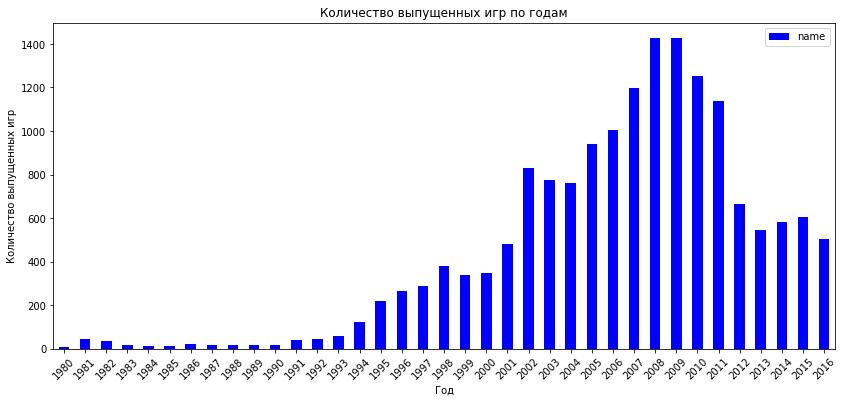

In [52]:
games.groupby("year_of_release")["name"].count().plot(kind = "bar", rot = 45, color = "b", figsize=(14, 6))
plt.ylabel('Количество выпущенных игр')
plt.xlabel('Год')
plt.legend(prop={'size': 10})
plt.title('Количество выпущенных игр по годам', size=12)
plt.show()

Основной рост выпуска игр начнается в 90-х годах. Посе 2009 года начинается спад. В 2012 ситуация стабилизируется и выпускается около 600 - 700 игр в год. Для прогнозирования продаж на 2017 по данным за все периоды можно судить о возможных тенденциях и масштабах ежегодных изменений. Можно, например, оценить стадию жизненного цикла платформы и спрогнозировать продажи. Конечно данные за все 36 лет не очень помогут, но последние 10 изучить важно.

### Выберим платформы с наибольшими суммарными продажами за весь период и построим распределение по годам

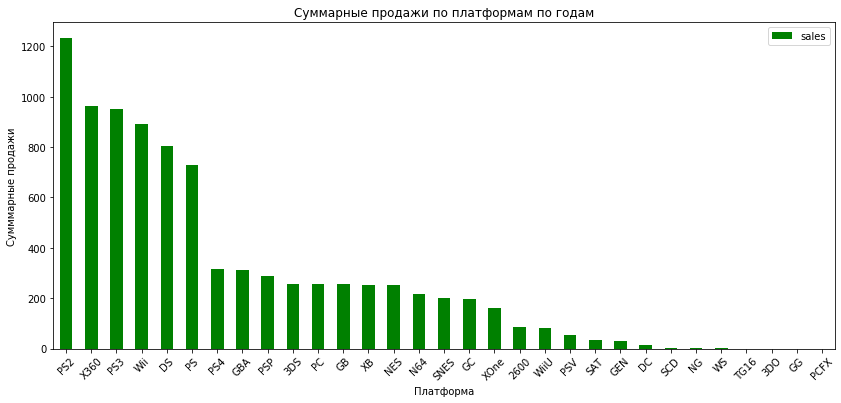

In [53]:
games.pivot_table(index = ['platform'], values = ['sales'],
   aggfunc = {'sales':'sum'}).sort_values('sales',
   ascending = False).plot(kind = "bar", rot = 45, color = "g", figsize=(14, 6))
plt.ylabel('Сумммарные продажи')
plt.xlabel('Платформа')
plt.legend(prop={'size': 10})
plt.title('Суммарные продажи по платформам по годам', size=12)
plt.show()

### Самые продаваемые платформы:
    

In [54]:
platform_top = games.pivot_table(index = ['platform'], values = ['sales'],
   aggfunc = {'sales':'sum'}).sort_values('sales', ascending = False).reset_index().head(6)
platform_top

,platform,sales
0,PS2,1233.56
1,X360,961.24
2,PS3,949.33
3,Wii,891.18
4,DS,802.78
5,PS,727.58


### Построим распределение продаж по платформам по годам

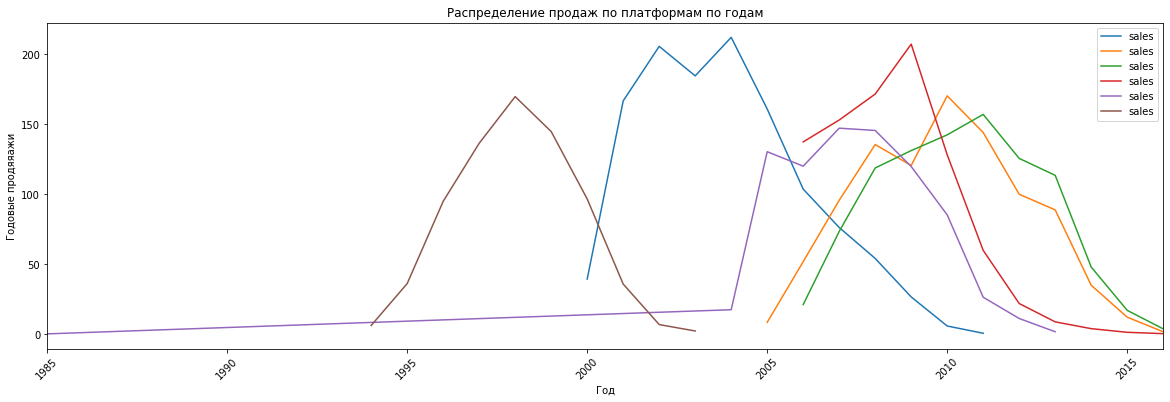

In [55]:
for platform in ["PS2", "X360", "PS3", "Wii", "DS", "PS"]:
    games.query('platform == @platform').groupby("year_of_release")["sales"].sum().plot(rot = 45, figsize=(20, 6))
plt.ylabel('Годовые продяяажи')
plt.xlabel('Год')
plt.legend(prop={'size': 10})
plt.title('Распределение продаж по платформам по годам', size=12)
plt.show()

Для красоты уберу артефакт из 1985 года

In [56]:
print(games.query('platform == "DS" and year_of_release == 1985'))

                                      name platform  year_of_release   genre  \
15719  Strongest Tokyo University Shogi DS       DS             1985  Action   

       na_sales  eu_sales  jp_sales  other_sales  critic_score  user_score  \
15719       0.0       0.0      0.02          0.0           NaN         NaN   

      rating  sales  
15719    NaN   0.02  


In [57]:
games.loc[15719]

name               Strongest Tokyo University Shogi DS
platform                                            DS
year_of_release                                   1985
genre                                           Action
na_sales                                             0
eu_sales                                             0
jp_sales                                          0.02
other_sales                                          0
critic_score                                       NaN
user_score                                         NaN
rating                                             NaN
sales                                             0.02
Name: 15719, dtype: object

In [58]:
games

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,sales
0,Wii Sports,Wii,2006,Sports,41.36,28.96,3.77,8.45,76.0,8.0,E,82.54
1,Super Mario Bros.,NES,1985,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN,40.24
2,Mario Kart Wii,Wii,2008,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E,35.52
3,Wii Sports Resort,Wii,2009,Sports,15.61,10.93,3.28,2.95,80.0,8.0,E,32.77
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN,31.38
...,...,...,...,...,...,...,...,...,...,...,...,...
16453,Samurai Warriors: Sanada Maru,PS3,2016,Action,0.00,0.00,0.01,0.00,NaN,NaN,NaN,0.01
16454,LMA Manager 2007,X360,2006,Sports,0.00,0.01,0.00,0.00,NaN,NaN,NaN,0.01
16455,Haitaka no Psychedelica,PSV,2016,Adventure,0.00,0.00,0.01,0.00,NaN,NaN,NaN,0.01
16456,Spirits & Spells,GBA,2003,Platform,0.01,0.00,0.00,0.00,NaN,NaN,NaN,0.01


In [59]:
games = games.drop(15719, axis=0)

In [60]:
games.columns = games.columns.str.lower()

In [61]:
games

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,sales
0,Wii Sports,Wii,2006,Sports,41.36,28.96,3.77,8.45,76.0,8.0,E,82.54
1,Super Mario Bros.,NES,1985,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN,40.24
2,Mario Kart Wii,Wii,2008,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E,35.52
3,Wii Sports Resort,Wii,2009,Sports,15.61,10.93,3.28,2.95,80.0,8.0,E,32.77
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN,31.38
...,...,...,...,...,...,...,...,...,...,...,...,...
16453,Samurai Warriors: Sanada Maru,PS3,2016,Action,0.00,0.00,0.01,0.00,NaN,NaN,NaN,0.01
16454,LMA Manager 2007,X360,2006,Sports,0.00,0.01,0.00,0.00,NaN,NaN,NaN,0.01
16455,Haitaka no Psychedelica,PSV,2016,Adventure,0.00,0.00,0.01,0.00,NaN,NaN,NaN,0.01
16456,Spirits & Spells,GBA,2003,Platform,0.01,0.00,0.00,0.00,NaN,NaN,NaN,0.01


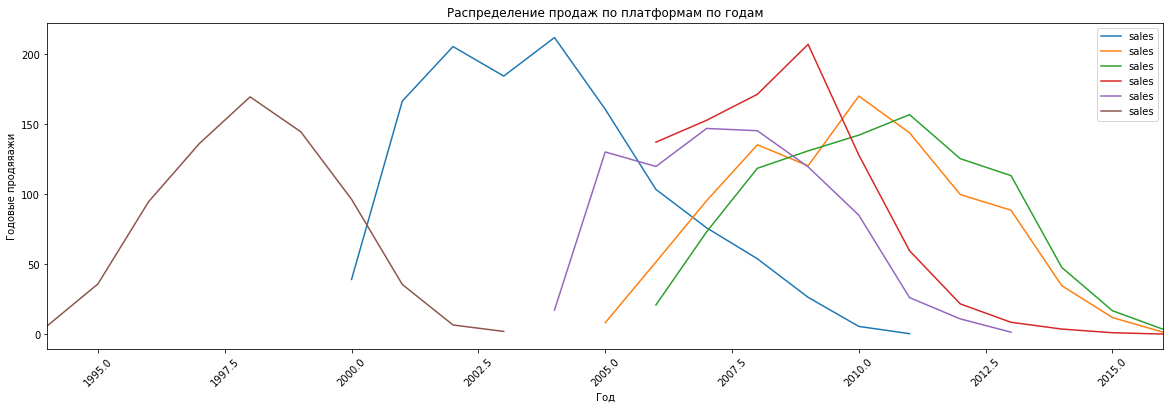

In [62]:
for platform in ["PS2", "X360", "PS3", "Wii", "DS", "PS"]:
    games.query('platform == @platform').groupby("year_of_release")["sales"].sum().plot(rot = 45, figsize=(20, 6))
plt.ylabel('Годовые продяяажи')
plt.xlabel('Год')
plt.legend(prop={'size': 10})
plt.title('Распределение продаж по платформам по годам', size=12)
plt.show()

Из графика видно, что средний жизненный цикл платформы составляет 10 лет.

### Возьмем данные за соответствующий актуальный период

Поскольку середина жизненного цикла платформы с максимумом продаж достигается в среднем к 5 годам жизни платформы, то анализ за период с 2011 года позволит увидеть на каком этапе жизненного цикла находятся платформы в 2016 году. Это и будет актуальный период.

### Определение платформ, лидирующих по продажам

Определим актуальные платформы

In [63]:
platform_top_2011 = games.query('year_of_release >= 2011 and platform != "PS2"').pivot_table(index = ['platform'], values = ['sales'],
   aggfunc = {'sales':'sum'}).sort_values('sales', ascending = False).reset_index()
platform_top_2011

,platform,sales
0,PS3,463.56
1,X360,380.38
2,PS4,314.14
3,3DS,257.81
4,XOne,159.32
5,PC,97.68
6,Wii,95.02
7,WiiU,82.19
8,PSV,53.81
9,DS,38.73


На рынке присутствуют 11 платформ, посмотрим как ведут себя их продажи.

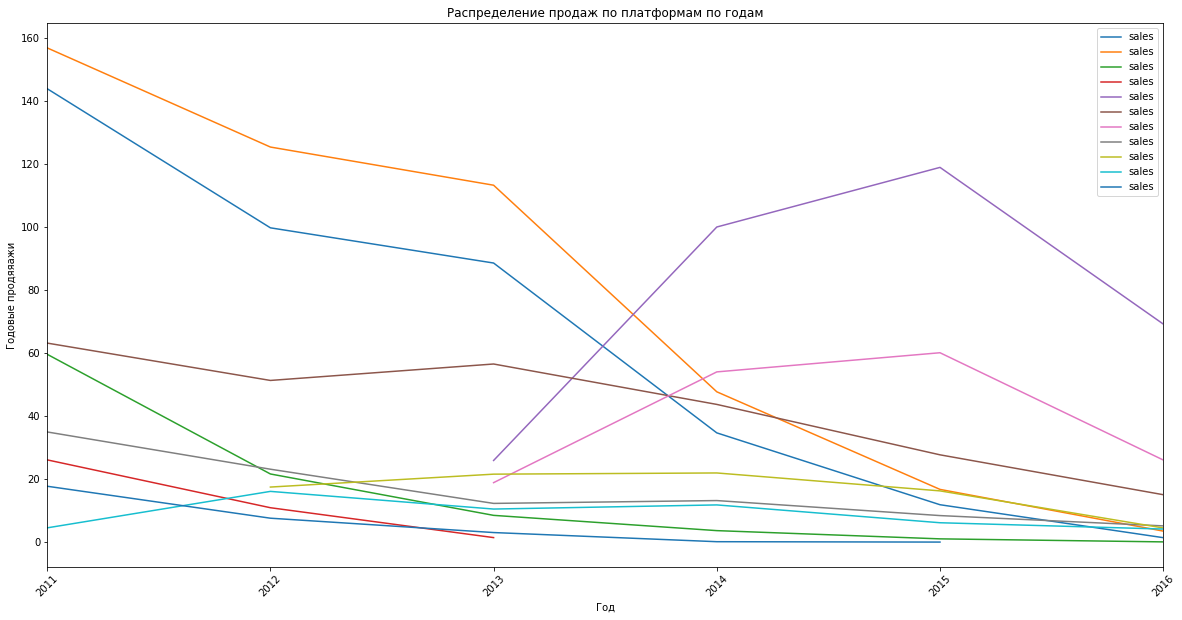

In [64]:
for platform in ["X360", "PS3", "Wii", "DS", "PS4", "3DS", "XOne", "PC", "WiiU", "PSV", "PSP"]:
    games.query('year_of_release >= 2011').query('platform == @platform').groupby("year_of_release")["sales"].sum().plot(rot = 45, figsize=(20, 10))
plt.ylabel('Годовые продяяажи')
plt.xlabel('Год')
plt.legend(prop={'size': 10})
plt.title('Распределение продаж по платформам по годам', size=12)
plt.show()

Из графика видно, что лидеры продаж - PS4 и XOne. Эти платформы находятся в 2016 году на 3 году жизни. Их падение в 2016 по-видимому связано с тем, что за этот год собрана не полная статистика. Остальные платформы падают.

## Построим график «ящик с усами» по глобальным продажам каждой игры и разбивкой по платформам

Такой вид диаграммы в удобной форме показывает медиану (или, если нужно, среднее), нижний и верхний квартили, минимальное и максимальное значение выборки и выбросы. Несколько таких ящиков можно нарисовать бок о бок, чтобы визуально сравнивать одно распределение с другим; их можно располагать как горизонтально, так и вертикально. Расстояния между различными частями ящика позволяют определить степень разброса (дисперсии) и асимметрии данных и выявить выбросы.

/opt/conda/lib/python3.7/site-packages/numpy/core/_asarray.py:83: VisibleDeprecationWarning:

Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray



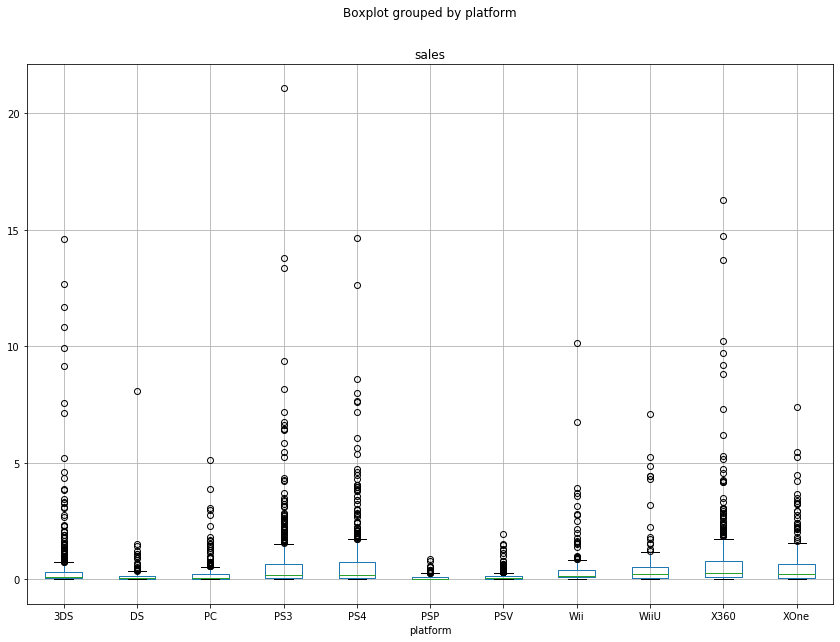

In [65]:
games.query('year_of_release >= 2011 and platform != "PS2"').boxplot('sales', by='platform', figsize=(14, 10))

Уберем выбросы более 4 млн. долларов и посмотрим сколько данных осталось.

In [66]:
games_clean = games.query('year_of_release >= 2013 and sales < 4 and platform != "PS2"')
print('После удаления выбросов осталось {:.1%} записей'.format((games_clean.shape[0])/games.query('year_of_release >= 2011').shape[0]))

После удаления выбросов осталось 54.2% записей


Построим график «ящик с усами» теперь по данным без выбросов

/opt/conda/lib/python3.7/site-packages/numpy/core/_asarray.py:83: VisibleDeprecationWarning:

Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray



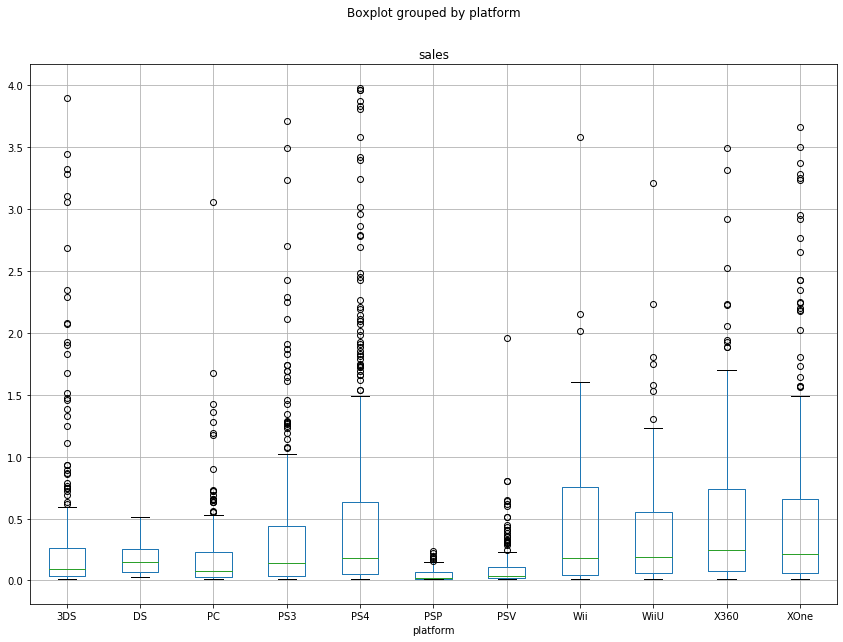

In [67]:
games_clean.boxplot('sales', by='platform', figsize=(14, 10))

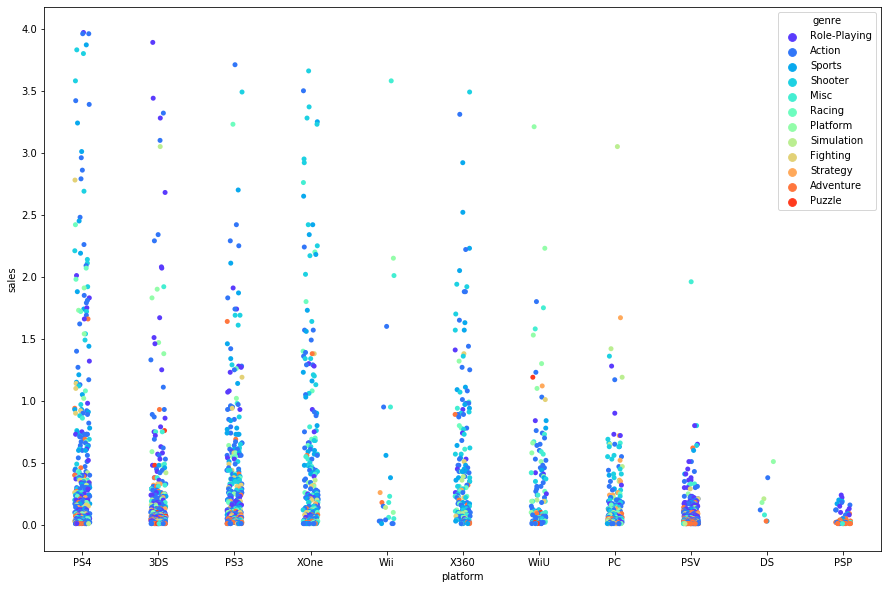

In [68]:
plt.subplots(figsize=(15,10))
sns.stripplot(x="platform", y="sales", data=games_clean, palette='rainbow', hue="genre")

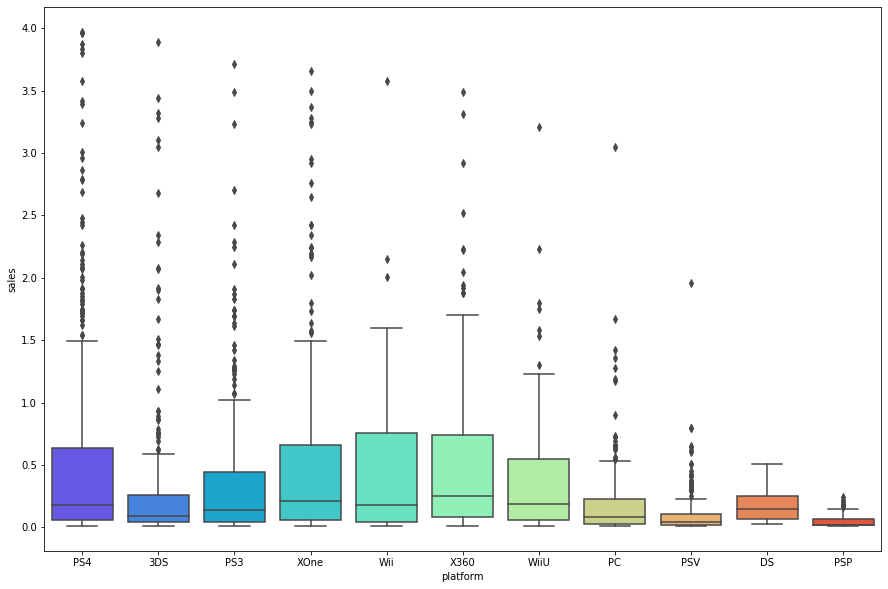

In [69]:
plt.subplots(figsize=(15,10))
sns.boxplot(x="platform", y="sales", data=games_clean, palette='rainbow')

Посмотрим на данные более пристально

In [70]:
games_clean_indikators = games_clean.groupby('platform')['sales'].aggregate(['sum', 'median', 'mean', 'count']).sort_values('sum', ascending = False)
games_clean_indikators

,sum,median,mean,count
platform,,,,
PS4,200.50,0.18,0.534667,375
XOne,132.49,0.21,0.547479,242
PS3,124.79,0.14,0.369201,338
X360,92.61,0.25,0.511657,181
3DS,92.47,0.09,0.311347,297
WiiU,43.91,0.19,0.395586,111
PC,39.43,0.08,0.208624,189
PSV,32.99,0.04,0.092151,358
Wii,13.66,0.18,0.593913,23


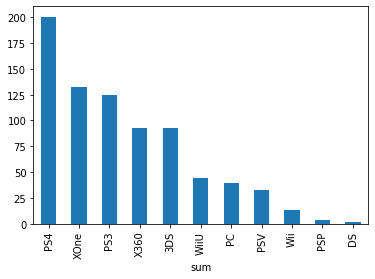

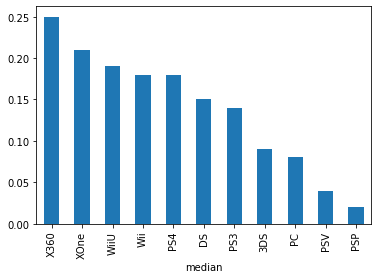

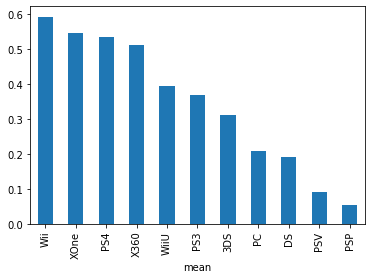

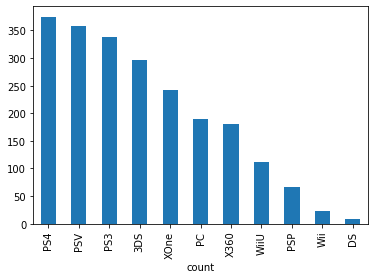

In [71]:
for a in games_clean_indikators.columns[0:5]:
    games_clean_indikators[a].sort_values(ascending = False).plot(kind = "bar", y = "platform")
    plt.xlabel(a)
    plt.show()

In [72]:
cor = games_clean.pivot_table(values='sales', index='platform', columns='year_of_release', aggfunc = {'sales':'sum'})
cor = cor.dropna()
cor_2 = games_clean.pivot_table(values='sales', index='platform', columns='year_of_release', aggfunc = {'sales':'count'})
cor_2 = cor_2.dropna()

In [73]:
cor

year_of_release,2013,2014,2015,2016
platform,,,,
3DS,32.16,24.53,27.78,8.00
PC,12.38,13.28,8.52,5.25
PS3,70.52,33.85,16.82,3.60
PS4,25.99,50.87,75.92,47.72
PSV,10.59,11.90,6.25,4.25
Wii,8.59,3.75,1.14,0.18
WiiU,17.33,10.07,11.91,4.60
X360,48.67,30.46,11.96,1.52
XOne,18.96,43.34,44.04,26.15


In [74]:
cor_2

year_of_release,2013,2014,2015,2016
platform,,,,
3DS,88.0,78.0,86.0,45.0
PC,38.0,47.0,50.0,54.0
PS3,122.0,105.0,73.0,38.0
PS4,16.0,67.0,132.0,160.0
PSV,63.0,100.0,110.0,85.0
Wii,12.0,6.0,4.0,1.0
WiiU,41.0,29.0,27.0,14.0
X360,71.0,62.0,35.0,13.0
XOne,19.0,59.0,77.0,87.0


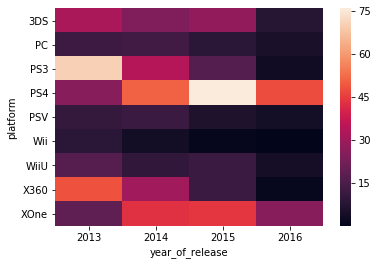

In [75]:
sns.heatmap(cor)

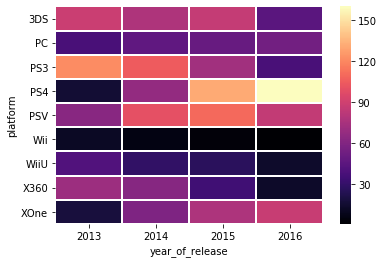

In [76]:
sns.heatmap(cor_2, cmap='magma',linecolor='white',linewidths=1)

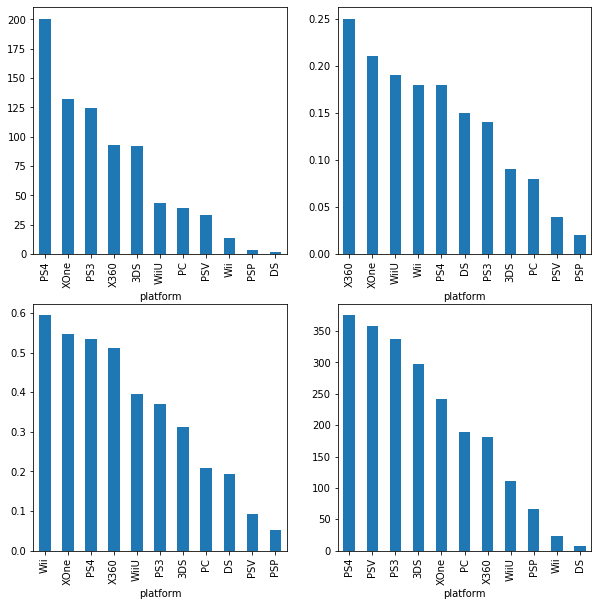

In [77]:
fig,axs = plt.subplots(figsize=(10,10), ncols=2, nrows=2)
games_clean_indikators["sum"].sort_values(ascending = False).plot(kind = "bar", y = "platform", ax = axs[0, 0])
games_clean_indikators["median"].sort_values(ascending = False).plot(kind = "bar", y = "platform", ax = axs[0, 1])
games_clean_indikators["mean"].sort_values(ascending = False).plot(kind = "bar", y = "platform", ax = axs[1, 0])
games_clean_indikators["count"].sort_values(ascending = False).plot(kind = "bar", y = "platform", ax = axs[1, 1])


### Гистограммы для категориальных переменных

В seaborn можно можно строить графики без предварительных расчетов

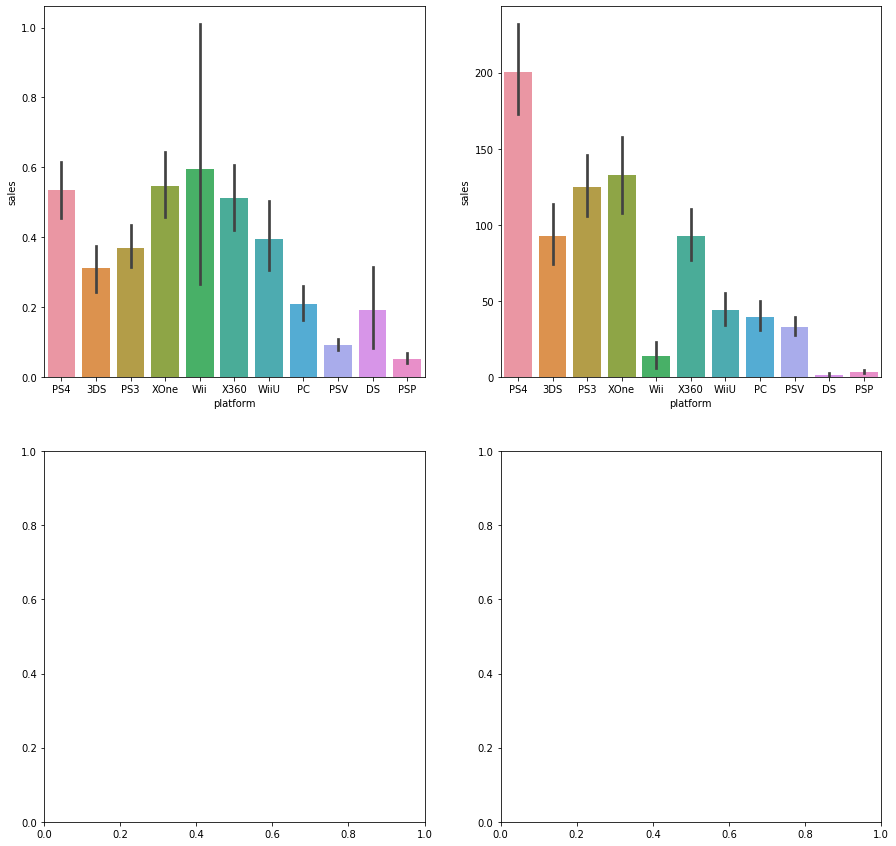

In [78]:
fig,axs = plt.subplots(figsize=(15,15), ncols=2, nrows=2)
sns.barplot(x = 'platform', y = 'sales', data = games_clean, ax = axs[0, 0])# по умолчанию рассчитывается средне
sns.barplot(x = 'platform', y = 'sales', data = games_clean, estimator=sum, ax = axs[0, 1])
#sns.barplot(x = 'platform', y = 'sales', data = games_clean, estimator=median, ax = axs[1, 0])
#sns.barplot(x = 'platform', y = 'sales', data = games_clean, estimator=count, ax = axs[1, 1])

### Определим разницу в продажах на разных платформах

In [79]:
s = 0
for a in range(1,11):
    s = s + (games_clean_indikators.reset_index().loc[a - 1]["sum"] - games_clean_indikators.reset_index().loc[a]["sum"])
    print("Платформа", games_clean_indikators.reset_index().loc[a - 1]["platform"],
          "принесла со всех игр на", round((games_clean_indikators.reset_index().loc[a - 1]["sum"] - games_clean_indikators.reset_index().loc[a]["sum"])),
          "млн. долларов больше, чем платформа", games_clean_indikators.reset_index().loc[a]["platform"])
print()    
print("Средняя разница в продажах между платформами составляет", round(s/10, 2), "млн. долларов")


Платформа PS4 принесла со всех игр на 68 млн. долларов больше, чем платформа XOne
Платформа XOne принесла со всех игр на 8 млн. долларов больше, чем платформа PS3
Платформа PS3 принесла со всех игр на 32 млн. долларов больше, чем платформа X360
Платформа X360 принесла со всех игр на 0 млн. долларов больше, чем платформа 3DS
Платформа 3DS принесла со всех игр на 49 млн. долларов больше, чем платформа WiiU
Платформа WiiU принесла со всех игр на 4 млн. долларов больше, чем платформа PC
Платформа PC принесла со всех игр на 6 млн. долларов больше, чем платформа PSV
Платформа PSV принесла со всех игр на 19 млн. долларов больше, чем платформа Wii
Платформа Wii принесла со всех игр на 10 млн. долларов больше, чем платформа PSP
Платформа PSP принесла со всех игр на 2 млн. долларов больше, чем платформа DS

Средняя разница в продажах между платформами составляет 19.9 млн. долларов


Таким образом и график и цифры показывают экспоненциальный рост продаж от менее успешных платформ к болеее успешным.

### Рассмотрим разницу в средних продажах на разных платформах

In [80]:
s = 0
games_clean_indikators = games_clean.groupby('platform')['sales'].aggregate(['sum', 'median', 'mean', 'count']).sort_values('mean', ascending = False)
for a in range(1,11):
    s = s + (games_clean_indikators.reset_index().loc[a - 1]["mean"] - games_clean_indikators.reset_index().loc[a]["mean"])
    print("Платформа", games_clean_indikators.reset_index().loc[a - 1]["platform"],
          "принесла в среднем с каждой игры на", round((games_clean_indikators.reset_index().loc[a - 1]["mean"] - games_clean_indikators.reset_index().loc[a]["mean"]), 2),
          "млн. долларов больше, чем платформа", games_clean_indikators.reset_index().loc[a]["platform"])
print()    
print("Средняя разница в продажах между платформами составляет", round(s/10, 3), "млн. долларов")


Платформа Wii принесла в среднем с каждой игры на 0.05 млн. долларов больше, чем платформа XOne
Платформа XOne принесла в среднем с каждой игры на 0.01 млн. долларов больше, чем платформа PS4
Платформа PS4 принесла в среднем с каждой игры на 0.02 млн. долларов больше, чем платформа X360
Платформа X360 принесла в среднем с каждой игры на 0.12 млн. долларов больше, чем платформа WiiU
Платформа WiiU принесла в среднем с каждой игры на 0.03 млн. долларов больше, чем платформа PS3
Платформа PS3 принесла в среднем с каждой игры на 0.06 млн. долларов больше, чем платформа 3DS
Платформа 3DS принесла в среднем с каждой игры на 0.1 млн. долларов больше, чем платформа PC
Платформа PC принесла в среднем с каждой игры на 0.02 млн. долларов больше, чем платформа DS
Платформа DS принесла в среднем с каждой игры на 0.1 млн. долларов больше, чем платформа PSV
Платформа PSV принесла в среднем с каждой игры на 0.04 млн. долларов больше, чем платформа PSP

Средняя разница в продажах между платформами сост

Таким образом мы видим, что средняя выручка с каждой игры на разных платформах отличалать не очень сильно. На графике вижно, что падение линейное и плавное.

## Посмотрите, как влияют на продажи внутри одной популярной платформы отзывы пользователей и критиков. Постройте диаграмму рассеяния

Создади фрейм для самой популярной платформы в 2016 году - PS4

In [81]:
games_clean_PS4 = games_clean.query('platform == "PS4"')
games_clean_PS4.head(1)

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,sales
302,The Witcher 3: Wild Hunt,PS4,2015,Role-Playing,1.02,2.13,0.23,0.59,92.0,9.2,M,3.97


Посмотрим зависимость продаж от отзывов критиков на платформе PS4 

Text(0.5, 1.0, 'Зависимость продаж от отзывов критиков')

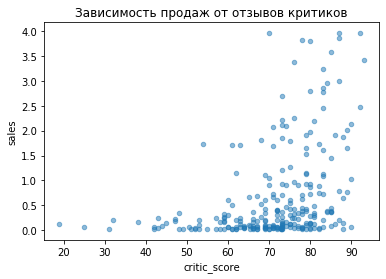

In [82]:
games_clean_PS4.plot.scatter('critic_score', 'sales', alpha = 0.5)
plt.title('Зависимость продаж от отзывов критиков')

In [83]:
sns.axes_style()

{'axes.facecolor': 'white',
 'axes.edgecolor': 'black',
 'axes.grid': False,
 'axes.axisbelow': 'line',
 'axes.labelcolor': 'black',
 'figure.facecolor': (1, 1, 1, 0),
 'grid.color': '#b0b0b0',
 'grid.linestyle': '-',
 'text.color': 'black',
 'xtick.color': 'black',
 'ytick.color': 'black',
 'xtick.direction': 'out',
 'ytick.direction': 'out',
 'lines.solid_capstyle': 'projecting',
 'patch.edgecolor': 'black',
 'image.cmap': 'viridis',
 'font.family': ['sans-serif'],
 'font.sans-serif': ['DejaVu Sans',
  'Bitstream Vera Sans',
  'Computer Modern Sans Serif',
  'Lucida Grande',
  'Verdana',
  'Geneva',
  'Lucid',
  'Arial',
  'Helvetica',
  'Avant Garde',
  'sans-serif'],
 'patch.force_edgecolor': False,
 'xtick.bottom': True,
 'xtick.top': False,
 'ytick.left': True,
 'ytick.right': False,
 'axes.spines.left': True,
 'axes.spines.bottom': True,
 'axes.spines.right': True,
 'axes.spines.top': True}

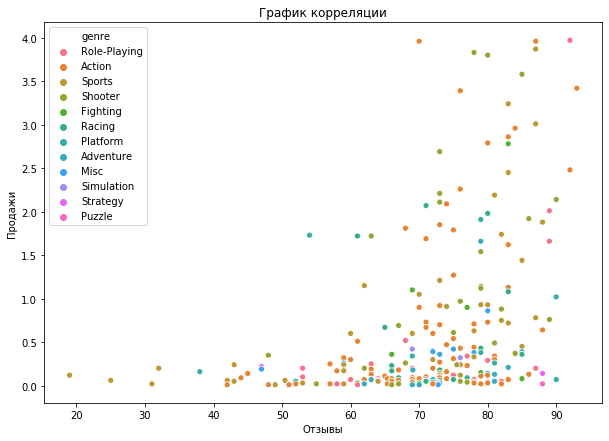

In [84]:
fig, ax = plt.subplots(figsize=(10,7))
sns.scatterplot(x = games_clean_PS4['critic_score'], y = games_clean_PS4['sales'], hue = games_clean_PS4['genre'], ax=ax)
ax.set_title("График корреляции")
plt.xlabel('Отзывы')
plt.ylabel('Продажи')

fig.savefig("filename.png", dpi=200)

In [85]:
games_clean_PS4

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,sales
302,The Witcher 3: Wild Hunt,PS4,2015,Role-Playing,1.02,2.13,0.23,0.59,92.0,9.2,M,3.97
303,Assassin's Creed: Unity,PS4,2014,Action,1.19,2.07,0.08,0.62,70.0,4.9,M,3.96
304,Batman: Arkham Knight,PS4,2015,Action,1.53,1.69,0.10,0.64,87.0,7.6,M,3.96
313,NBA 2K16,PS4,2015,Sports,2.49,0.66,0.03,0.69,87.0,6.7,E10+,3.87
322,Call of Duty: Ghosts,PS4,2013,Shooter,1.78,1.43,0.05,0.57,78.0,3.7,M,3.83
...,...,...,...,...,...,...,...,...,...,...,...,...
16244,Root Letter,PS4,2016,Adventure,0.00,0.00,0.01,0.00,69.0,7.5,NaN,0.01
16247,Shin Hayarigami 2,PS4,2016,Adventure,0.00,0.00,0.01,0.00,NaN,NaN,NaN,0.01
16269,Dungeons 2,PS4,2016,Role-Playing,0.01,0.00,0.00,0.00,61.0,7.9,T,0.01
16273,Carmageddon: Max Damage,PS4,2016,Action,0.01,0.00,0.00,0.00,51.0,5.5,M,0.01


In [86]:
px.scatter(games_clean_PS4, x="critic_score", y="sales",  color="genre", size="jp_sales")

In [87]:
fig = px.scatter_3d(games_clean.query('platform == "XOne"').dropna(axis='index', how='any', subset=['user_score']).reset_index(drop=True), x="critic_score", y="sales", z="user_score", color="platform", size="sales", hover_name="sales",
                  symbol="user_score", color_discrete_map = {"critic_score": "blue", "sales": "green", "user_score":"red"})
fig.show()

Посмотрим зависимость продаж от отзывов пользователей на платформе PS4

Text(0.5, 1.0, 'Зависимость продаж от отзывов пользователей')

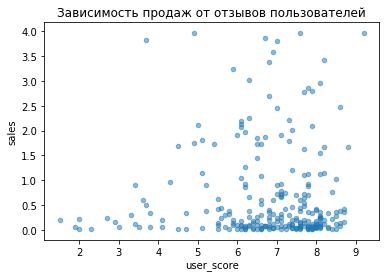

In [88]:
games_clean_PS4.plot.scatter('user_score', 'sales', alpha = 0.5)
plt.title('Зависимость продаж от отзывов пользователей')

Посмотрим корреляцию между отзывами пользователей и продажами

In [89]:
games_clean_PS4.corr()["user_score"].sort_values(ascending = False)

user_score         1.000000
critic_score       0.595366
jp_sales           0.186365
year_of_release    0.167492
eu_sales           0.031655
sales              0.015400
other_sales        0.003981
na_sales          -0.026688
Name: user_score, dtype: float64

Посмотрим корреляцию между отзывами критиков и продажами

In [90]:
games_clean_PS4.corr()["critic_score"].sort_values(ascending = False)

critic_score       1.000000
user_score         0.595366
other_sales        0.390211
sales              0.389268
na_sales           0.377841
eu_sales           0.329249
jp_sales           0.252300
year_of_release   -0.012757
Name: critic_score, dtype: float64

Мы видим, что зависимость продаж от отзывов пользователей на платформе PS4 практически отсутсвует. Коэффициент корреляции = 0,02. А вот зависимость продаж от отзывов критиков на платформе PS4 - средняя. Коэффициент корреляции = 0,39

### Соотнесите выводы с продажами игр на других платформах

Создадим фрейм для второй по популярности платформы в 2016 году - XOne

In [91]:
games_clean_XOne = games_clean.query('platform == "XOne"')
games_clean_XOne.head(1)

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,sales
341,Star Wars Battlefront (2015),XOne,2015,Shooter,2.04,1.28,0.02,0.32,NaN,NaN,NaN,3.66


Посмотрим зависимость продаж от отзывов критиков на платформе XOne 

Text(0.5, 1.0, 'Зависимость продаж от отзывов критиков')

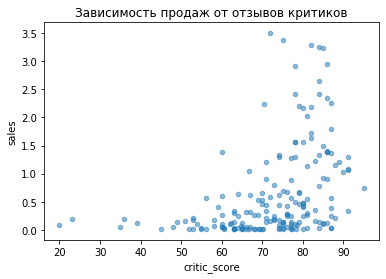

In [92]:
games_clean_XOne.plot.scatter('critic_score', 'sales', alpha = 0.5)
plt.title('Зависимость продаж от отзывов критиков')

Посмотрим зависимость продаж от отзывов пользователей на платформе XOne

Text(0.5, 1.0, 'Зависимость продаж от отзывов пользователей')

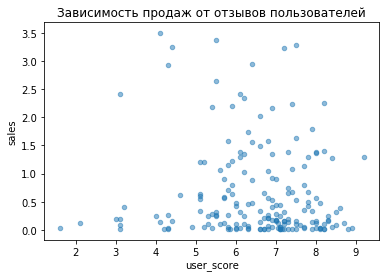

In [93]:
games_clean_XOne.plot.scatter('user_score', 'sales', alpha = 0.5)
plt.title('Зависимость продаж от отзывов пользователей')

Посмотрим корреляцию между отзывами пользователей и продажами

In [94]:
games_clean_XOne.corr()["user_score"].sort_values(ascending = False)

user_score         1.000000
critic_score       0.478904
jp_sales           0.089016
year_of_release    0.085596
eu_sales          -0.078534
na_sales          -0.081566
other_sales       -0.087074
sales             -0.089107
Name: user_score, dtype: float64

Посмотрим корреляцию между отзывами критиков и продажами

In [95]:
games_clean_XOne.corr()["critic_score"].sort_values(ascending = False)

critic_score       1.000000
user_score         0.478904
sales              0.400475
other_sales        0.393755
na_sales           0.364403
eu_sales           0.345857
jp_sales           0.191179
year_of_release    0.073334
Name: critic_score, dtype: float64

Мы видим, что зависимость продаж от отзывов пользователей на платформе One практически отсутсвует. Коэффициент корреляции = -0.09. А вот зависимость продаж от отзывов критиков на платформе - средняя. Коэффициент корреляции = 0,4

### Применение библиотеки seaborn 

Посмотрим совместное распределение по двум переменным с помощью Функции jointplot(). Она имеет параметр kind который может принимать следующие значения:

“scatter”
“reg”
“resid”
“kde”
“hex”

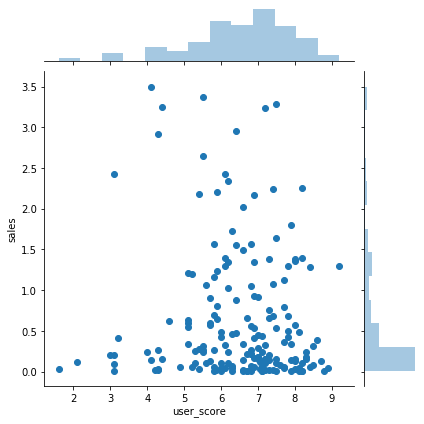

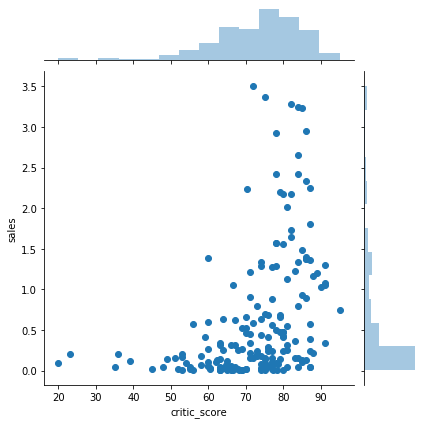

In [96]:
sns.jointplot(x='user_score', y='sales', data=games_clean_XOne, kind='scatter')
plt.show()
sns.jointplot(x='critic_score', y='sales', data=games_clean_XOne, kind='scatter')
plt.show()

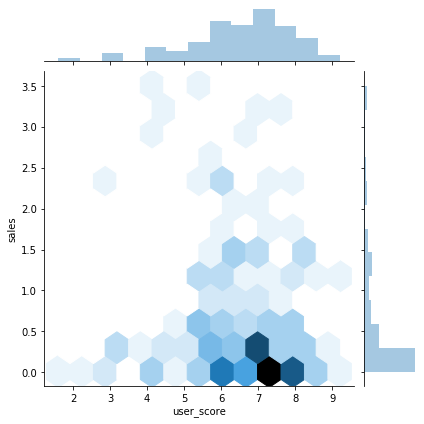

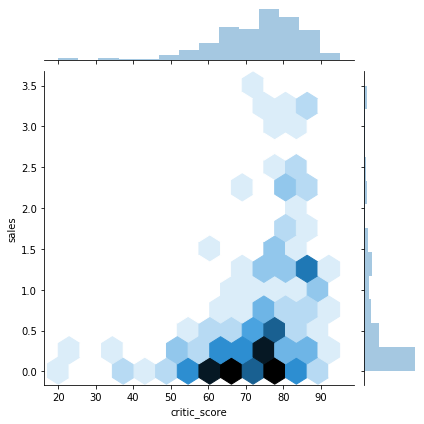

In [97]:
sns.jointplot(x='user_score', y='sales', data=games_clean_XOne, kind='hex')
plt.show()
sns.jointplot(x='critic_score', y='sales', data=games_clean_XOne, kind='hex')
plt.show()

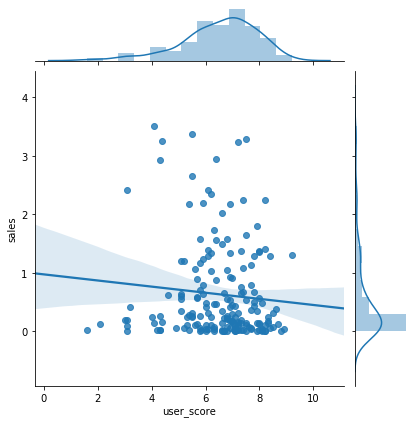

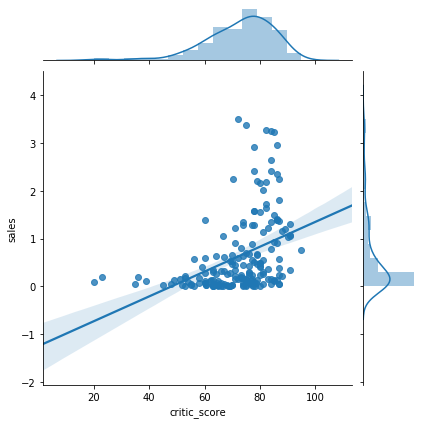

In [98]:
sns.jointplot(x='user_score', y='sales', data=games_clean_XOne, kind='reg')
plt.show()
sns.jointplot(x='critic_score', y='sales', data=games_clean_XOne, kind='reg')
plt.show()

Плотность распределения по двум переменным даёт нам градиент. Градиент — вектор, своим направлением указывающий направление наибольшего возрастания некоторой величины \varphiφ , значение которой меняется от одной точки пространства к другой (скалярного поля), а по величине (модулю) равный скорости роста этой величины в этом направлении.

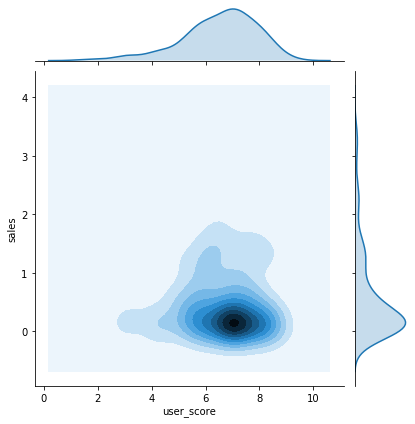

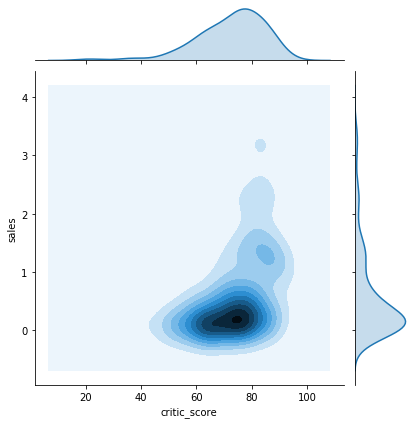

In [99]:
sns.jointplot(x='user_score', y='sales', data=games_clean_XOne, kind='kde')
plt.show()
sns.jointplot(x='critic_score', y='sales', data=games_clean_XOne, kind='kde')
plt.show()

Посмотрим отношения между некоторыми парами переменными с помощью pairplot

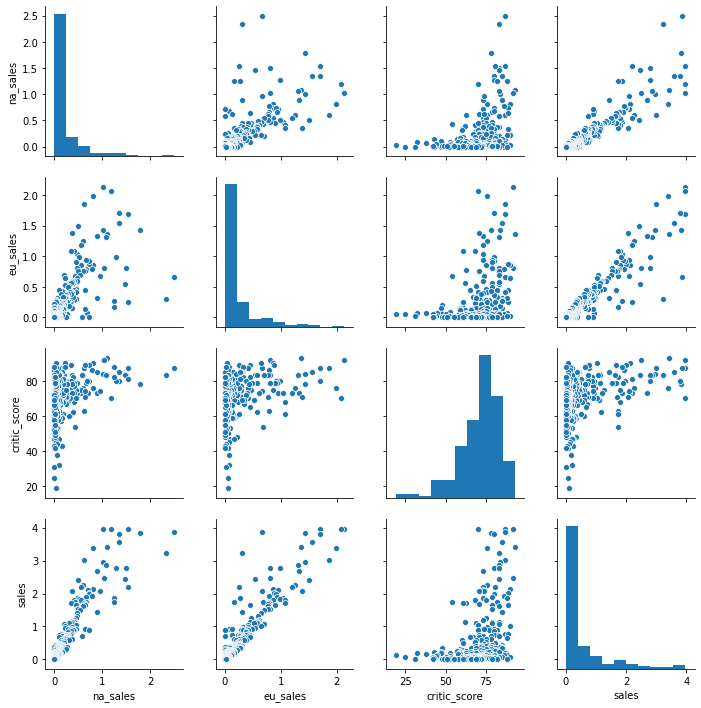

In [100]:
sns.pairplot(games_clean_PS4[["na_sales", "eu_sales", "critic_score", "sales"]])

## Посмотрим на общее распределение игр по жанрам.

In [101]:
games_clean.groupby("genre")['sales'].sum().sort_values(ascending = False)

genre
Action          242.62
Shooter         129.28
Sports          113.43
Role-Playing    101.08
Misc             44.05
Platform         38.31
Racing           32.80
Adventure        23.64
Fighting         22.89
Simulation       16.54
Strategy         10.08
Puzzle            3.17
Name: sales, dtype: float64

Самые прибыльные жанры:
* Action
* Shooter
* Sports
* Role-Playing


# 4. Составление портрета пользователя каждого региона<a id='040'>

## Определите для пользователя каждого региона (NA, EU, JP) cамые популярные платформы (топ-5).


Посмотрим на продажи по платформам в разных ргионах

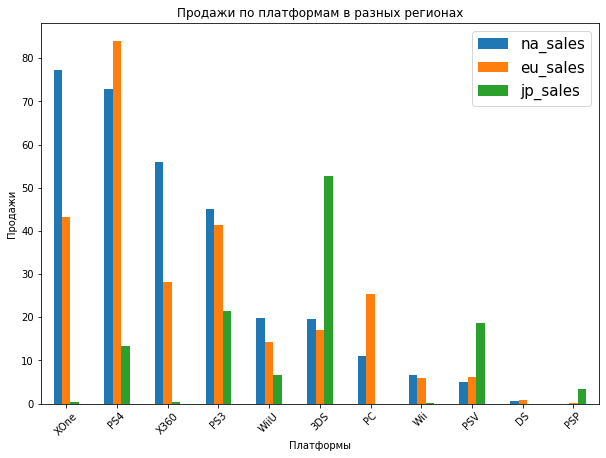

In [102]:
games_clean_countries = games_clean.groupby("platform")['na_sales', "eu_sales", "jp_sales"].sum().sort_values('na_sales', ascending = False)
games_clean_countries.plot(rot = 45, kind = "bar", figsize = (10,7))
plt.ylabel('Продажи')
plt.xlabel('Платформы')
plt.legend(prop={'size': 15})
plt.title('Продажи по платформам в разных регионах', size=12)
plt.show()

Видим, что платформы имеют неодинаковую популятность в разных странах. Определим ТОП-5 платформ в каждой стране. 

ТОП-5 продаж по платформам в регионе "Северная Америка"
platform
XOne    77.21
PS4     72.83
X360    55.88
PS3     45.02
WiiU    19.81
Name: na_sales, dtype: float64

ТОП-5 продаж по платформам в регионе "Европа"
platform
PS4     83.95
XOne    43.15
PS3     41.35
X360    28.17
PC      25.36
Name: eu_sales, dtype: float64

ТОП-5 продаж по платформам в регионе "Япония"
platform
3DS     52.66
PS3     21.41
PSV     18.59
PS4     13.22
WiiU     6.60
Name: jp_sales, dtype: float64



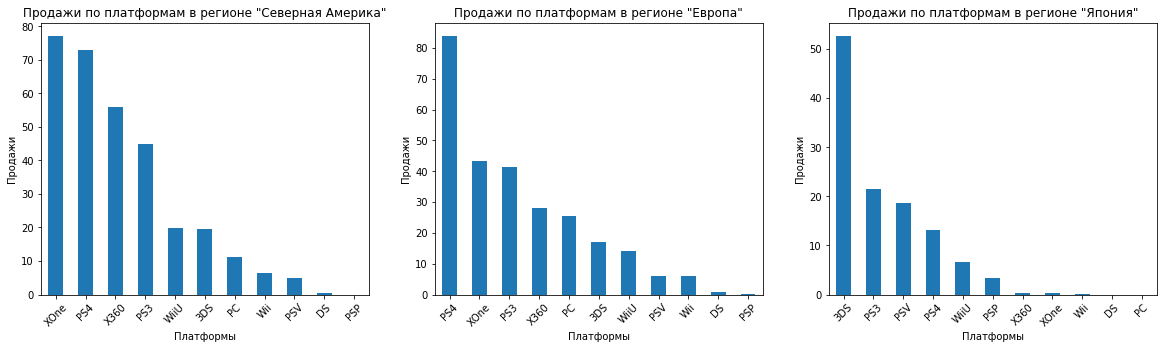

In [103]:
countries = {'na_sales':'"Северная Америка"', 'eu_sales':'"Европа"', 'jp_sales':'"Япония"'}
country = games_clean_countries.columns[0:4]
position = [0, 1, 2]
for country, position in zip(country, position):
    games_clean_countries[country].sort_values(ascending = False).plot(rot = 45, kind = "bar", y = "platform", figsize = (20, 5), ax = plt.subplot2grid((1,3), (0,position), colspan=1))
    plt.ylabel('Продажи')
    plt.xlabel('Платформы')
    plt.title("Продажи по платформам в регионе {:}".format(countries[country]), size=12)
    print("ТОП-5 продаж по платформам в регионе", countries[country])
    print(games_clean_countries[country].sort_values(ascending = False).head(5))
    print()

### Опредилим доли продаж каждой платформы в различных регионах

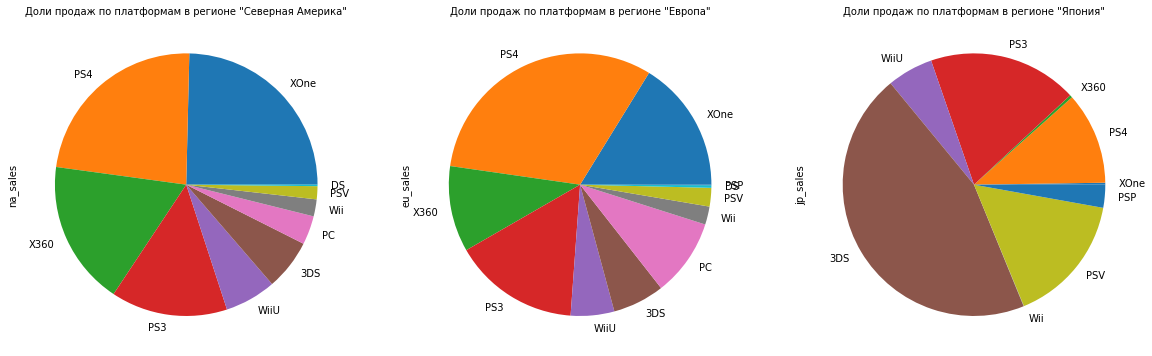

In [104]:
countries = {'na_sales':'"Северная Америка"', 'eu_sales':'"Европа"', 'jp_sales':'"Япония"'}
country = games_clean_countries.columns[0:4]
position = [0, 1, 2]
for country, position in zip(country, position):
    games_clean_countries[country].plot(kind = "pie", y = "platform", figsize = (20, 15), ax = plt.subplot2grid((1,3), (0,position), colspan=1))
    plt.title("Доли продаж по платформам в регионе {:}".format(countries[country]), size=10)
    

Промежуточные выводы:
* В трех регионах на первом месте по продажам стоят разные платформы
* В пятерку самых продаваемых платформ одновременно по всем регионам входит только две платформы - PS4 и PS3
* Ближе всего по структуре продаж Северная Америка и Европа. У них в пятерке самых продаваемых платформ совпадает 4 платформы, но они имеют разные доли в этих регионах

### Определим самые популярные жанры (топ-5)

Посмотрим на продажи по жанрам в разных ргионах

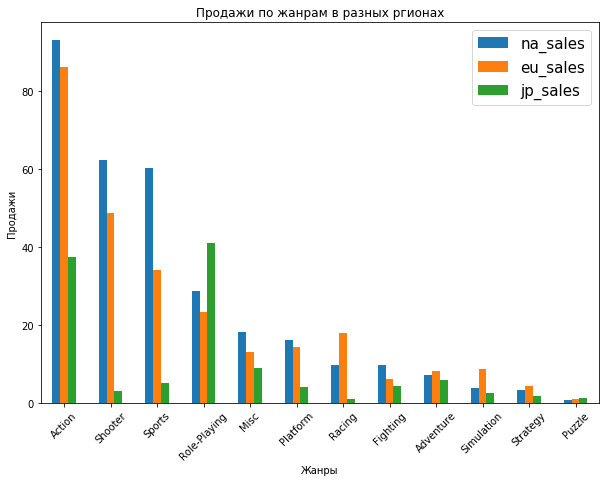

In [105]:
games_clean_genre = games_clean.groupby("genre")['na_sales', "eu_sales", "jp_sales"].sum().sort_values('na_sales', ascending = False)
games_clean_genre.plot(rot = 45, kind = "bar", figsize = (10,7))
plt.ylabel('Продажи')
plt.xlabel('Жанры')
plt.legend(prop={'size': 15})
plt.title('Продажи по жанрам в разных ргионах', size=12)
plt.show()

Видим, что жанры имеют неодинаковую популятность в разных странах. Определим ТОП-5 жанров в каждой стране. 

ТОП-5 жанров в регионе "Северная Америка"
genre
Action          93.04
Shooter         62.44
Sports          60.41
Role-Playing    28.75
Misc            18.28
Name: na_sales, dtype: float64

ТОП-5 жанров в регионе "Европа"
genre
Action          86.22
Shooter         48.79
Sports          34.17
Role-Playing    23.25
Racing          18.04
Name: eu_sales, dtype: float64

ТОП-5 жанров в регионе "Япония"
genre
Role-Playing    41.08
Action          37.42
Misc             9.04
Adventure        5.82
Sports           5.10
Name: jp_sales, dtype: float64



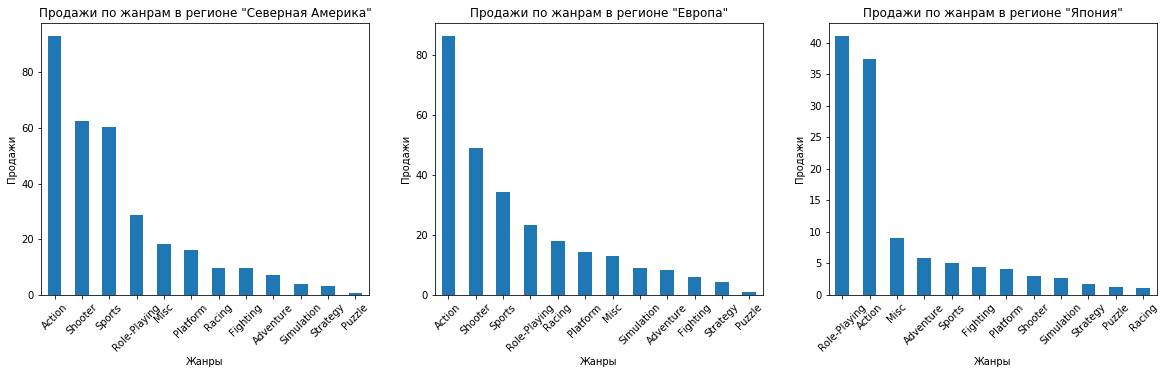

In [106]:
countries = {'na_sales':'"Северная Америка"', 'eu_sales':'"Европа"', 'jp_sales':'"Япония"'}
country = games_clean_countries.columns[0:4]
position = [0, 1, 2]
for country, position in zip(country, position):
    games_clean_genre[country].sort_values(ascending = False).plot(rot = 45, kind = "bar", y = "platform", figsize = (20, 5), ax = plt.subplot2grid((1,3), (0,position), colspan=1))
    plt.ylabel('Продажи')
    plt.xlabel('Жанры')
    plt.title("Продажи по жанрам в регионе {:}".format(countries[country]), size=12)
    print("ТОП-5 жанров в регионе", countries[country])
    print(games_clean_genre[country].sort_values(ascending = False).head(5))
    print()


### Опредилим доли продаж игр каждого жанра в различных регионах

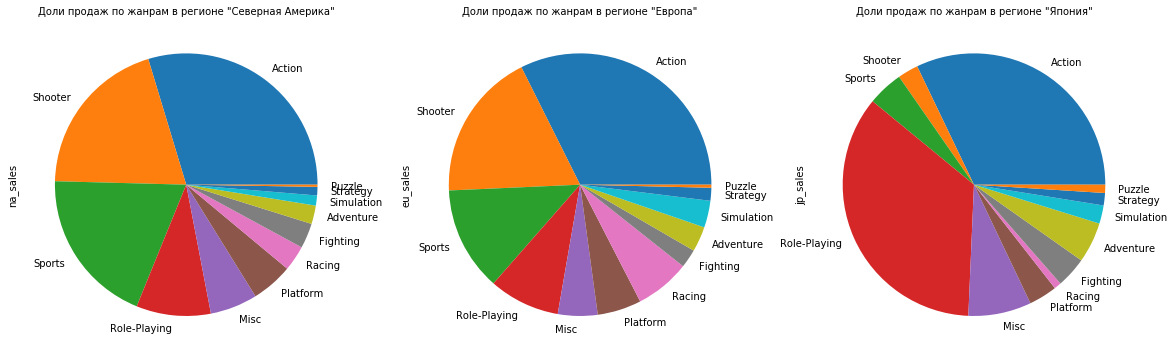

In [107]:
countries = {'na_sales':'"Северная Америка"', 'eu_sales':'"Европа"', 'jp_sales':'"Япония"'}
country = games_clean_countries.columns[0:4]
position = [0, 1, 2]
for country, position in zip(country, position):
    games_clean_genre[country].plot(kind = "pie", y = "platform", figsize = (20, 15), ax = plt.subplot2grid((1,3), (0,position), colspan=1))
    plt.title("Доли продаж по жанрам в регионе {:}".format(countries[country]), size=10)

Промежуточные выводы:
* В трех регионах на первом месте по продажам стоят разные жанры
* В пятерку самых продаваемых жанров одновременно по всем регионам входит три жанра: Action, Sports, Role-Playing 
* Ближе всего по структуре продаж с точки зрения жанров Северная Америка и Европа. У них в пятерке самых продаваемых жанров совпадает 4 жанра, но они имеют разные доли в этих регионах

## Влияет ли рейтинг ESRB на продажи в отдельном регионе?

Посмотрим как отличаются продажи в зависимости от рейтинга ESRB в разных ргионах

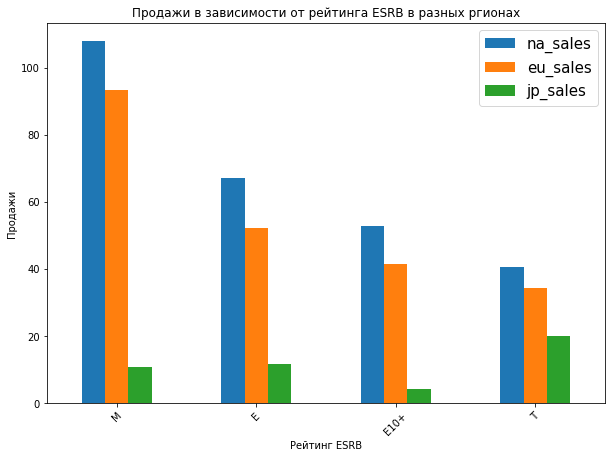

In [108]:
games_clean_ESRB = games_clean.groupby("rating")['na_sales', "eu_sales", "jp_sales"].sum().sort_values('na_sales', ascending = False)
games_clean_ESRB.plot(rot = 45, kind = "bar", figsize = (10,7))
plt.ylabel('Продажи')
plt.xlabel('Рейтинг ESRB')
plt.legend(prop={'size': 15})
plt.title('Продажи в зависимости от рейтинга ESRB в разных ргионах', size=12)
plt.show()

Видим, что рейтинги имеют неодинаковую популятность в разных странах. Определим ТОП-5 рейтингов в каждой стране. 

ТОП-5 рейтингов в регионе "Северная Америка"
rating
M       107.88
E        67.13
E10+     52.70
T        40.60
Name: na_sales, dtype: float64

ТОП-5 рейтингов в регионе "Европа"
rating
M       93.33
E       52.31
E10+    41.51
T       34.40
Name: eu_sales, dtype: float64

ТОП-5 рейтингов в регионе "Япония"
rating
T       20.13
E       11.71
M       10.83
E10+     4.43
Name: jp_sales, dtype: float64



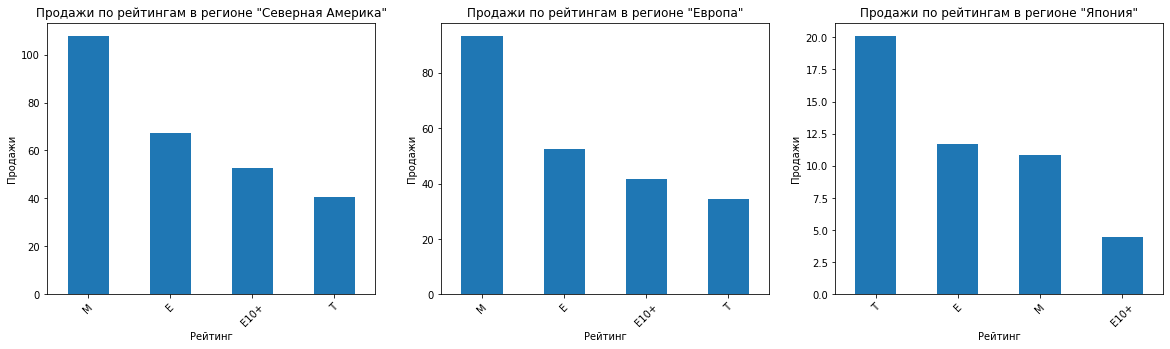

In [109]:
countries = {'na_sales':'"Северная Америка"', 'eu_sales':'"Европа"', 'jp_sales':'"Япония"'}
country = games_clean_countries.columns[0:4]
position = [0, 1, 2]
for country, position in zip(country, position):
    games_clean_ESRB[country].sort_values(ascending = False).plot(rot = 45, kind = "bar", y = "platform", figsize = (20, 5), ax = plt.subplot2grid((1,3), (0,position), colspan=1))
    plt.ylabel('Продажи')
    plt.xlabel('Рейтинг')
    plt.title("Продажи по рейтингам в регионе {:}".format(countries[country]), size=12)
    print("ТОП-5 рейтингов в регионе", countries[country])
    print(games_clean_ESRB[country].sort_values(ascending = False).head(5))
    print()
    

### Опредилим доли продаж по каждому рейтингу в различных регионах

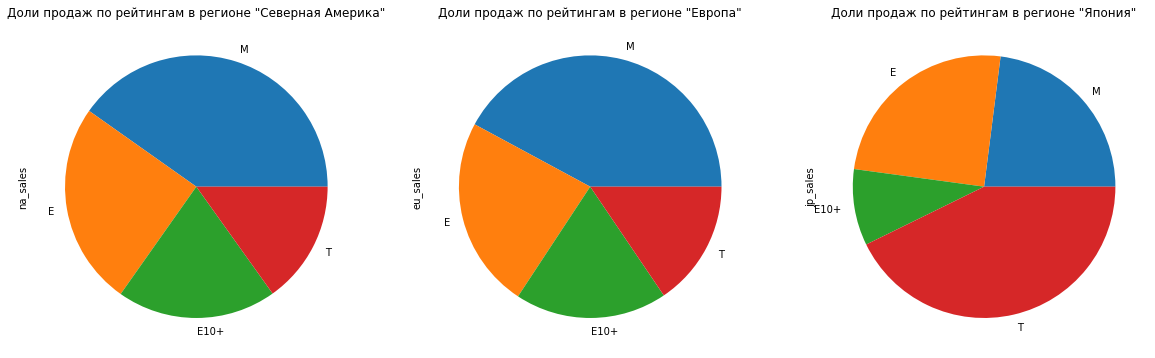

In [110]:
countries = {'na_sales':'"Северная Америка"', 'eu_sales':'"Европа"', 'jp_sales':'"Япония"'}
country = games_clean_countries.columns[0:4]
position = [0, 1, 2]
for country, position in zip(country, position):
    games_clean_ESRB[country].plot(kind = "pie", y = "platform", figsize = (20, 20), ax = plt.subplot2grid((1,3), (0,position), colspan=1))
    plt.title("Доли продаж по рейтингам в регионе {:}".format(countries[country]), size=12)

Промежуточные выводы:
* Ближе всего по структуре продаж Северная Америка и Европа. Самые продаваеые игры там имеют рейтинг «M» («Mature») — «Для взрослых»
* Самые продаваемые игры в Японии имеют рейтинг «T» («Teen») — «Подросткам»

# 5. Проверка гипотез<a id='050'>

Проверим две гипотезы:
* Средние пользовательские рейтинги платформ Xbox One и PC одинаковые
* Средние пользовательские рейтинги жанров Action и Sports разные

## Проверка гипотезы: "Средние пользовательские рейтинги платформ Xbox One и PC одинаковые"

Данная гипотеза отностся к типичной гипотезе:
* средние двух генеральных совокупностей равны между собой

Таким образом имеем:
* Нулевую гипотезу - Средние пользовательские рейтинги платформ Xbox One и PC равны
* Альтернативную гипотезу - Средние пользовательские рейтинги платформ Xbox One и PC не равны

Проверим эту нулевую гипотезу. Возмем alpha = 0.05, по 2,5% с каждой стороны нам вполне хватит. equal_var = True, поскольку выборки схожи и дисперсии выборок не сильно отличаются.

In [111]:
alpha = 0.05 # критический уровень статистической значимости
            # если p-value окажется меньше него - отвергнем гипотезу

results = st.ttest_ind(games_clean.query('platform == "XOne"')["user_score"], games_clean.query('platform == "PC"')["user_score"], nan_policy='omit')

print('p-значение:', results.pvalue)

if (results.pvalue < alpha):
    print("Отвергаем нулевую гипотезу")
else:
    print("Не получилось отвергнуть нулевую гипотезу")

p-значение: 0.1381526875631014
Не получилось отвергнуть нулевую гипотезу


Таким образом мы обнаружили вероятность 13,8%, что различие средних пользовательских рейтингов может быть случайным. Такая большая вероятность позволяет нам делать вывод об отсутсвии значимого различии между рейтингами разных платформ. Т.е. мы будем придерживаться нулевой гипотезы, о том, что средние пользовательские рейтинги платформ Xbox One и PC равны. 

Но нужно помнить, что данные могут лишь не противоречить гипотезе или, наоборот, показывать крайне маловероятные результаты. Но и в том, и в другом случае нет оснований утверждать, что выдвинутая гипотеза доказана.

Посмторим на изучаемые выборки с помощию диаграммы размаха

/opt/conda/lib/python3.7/site-packages/numpy/core/_asarray.py:83: VisibleDeprecationWarning:

Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray



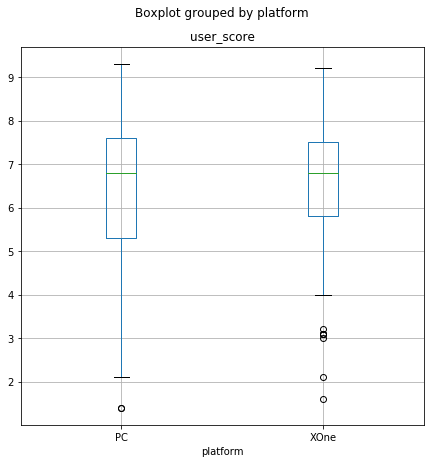

In [112]:
games_clean.query('platform == "XOne" or platform == "PC"').boxplot("user_score", by = "platform", figsize = (7, 7))
plt.show()

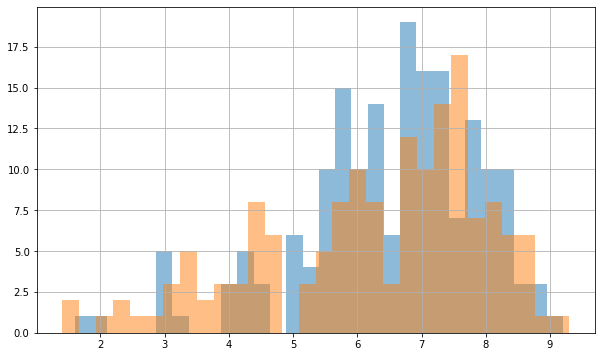

In [113]:
games_clean.query('platform == "XOne"')["user_score"].hist(bins = 30, alpha = 0.5, figsize = (10, 6))
games_clean.query('platform == "PC"')["user_score"].hist(bins = 30, alpha = 0.5)

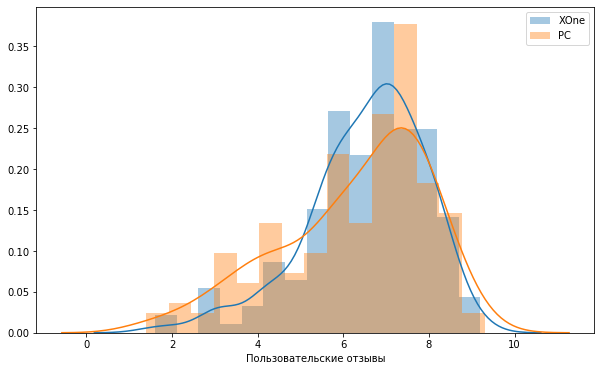

In [114]:
b = games_clean.query('platform == "XOne"').dropna(axis='index', how='any', subset=['user_score']).reset_index(drop=True)
c = games_clean.query('platform == "PC"').dropna(axis='index', how='any', subset=['user_score']).reset_index(drop=True)
plt.subplots(figsize = (10, 6))
sns.distplot(b['user_score'], bins = 15, label = "XOne")
sns.distplot(c['user_score'], bins = 15, label = "PC")
plt.xlabel('Пользовательские отзывы')
plt.legend()
plt.show()

Мы видим, что распределение данных двух выборок очень похожим "ящике". У них совпадают медианы, ящики и почти совпадают усы. Посмотрим на числовое описание данных.

In [115]:
games_clean.query('platform == "XOne"')["user_score"].describe()

count    182.000000
mean       6.528087
std        1.377213
min        1.600000
25%        5.800000
50%        6.800000
75%        7.500000
max        9.200000
Name: user_score, dtype: float64

In [116]:
games_clean.query('platform == "PC"')["user_score"].describe()

count    156.000000
mean       6.276025
std        1.738560
min        1.400000
25%        5.300000
50%        6.800000
75%        7.600000
max        9.300000
Name: user_score, dtype: float64

Средние очень близки и стандартное отклонение тоже почти одинакове.

## Проверка гипотезы: "Средние пользовательские рейтинги жанров Action и Sports разные"

Данная гипотеза отностся к типичной гипотезе:
* средние двух генеральных совокупностей равны между собой

Таким образом имеем:
* Нулевую гипотезу - Средние пользовательские рейтинги жанров Action и Sports равны
* Альтернативную гипотезу - Средние пользовательские рейтинги жанров Action и Sports не равны

Проверим эту нулевую гипотезу. Возмем alpha = 0.05, по 2,5% с каждой стороны нам вполне хватит. equal_var = True, поскольку выборки схожи и дисперсии выборок не сильно отличаются.

In [117]:
alpha = 0.05 # критический уровень статистической значимости
            # если p-value окажется меньше него - отвергнем гипотезу

results = st.ttest_ind(games_clean.query('genre == "Action"')["user_score"], games_clean.query('genre == "Sports"')["user_score"], nan_policy='omit')

print('p-значение:', results.pvalue)

if (results.pvalue < alpha):
    print("Отвергаем нулевую гипотезу")
else:
    print("Не получилось отвергнуть нулевую гипотезу")

p-значение: 1.0696918519521934e-25
Отвергаем нулевую гипотезу


Таким образом мы обнаружили слишком маленькую вероятность, что различие пользовательских рейтингов жанров Action и Sports может быть случайным. Эта слишком маленькая вероятность позволяет нам делать вывод о значимом различии между рейтингами. Т.е. мы будем придерживаться альтернативной гипотезы, о том, что средние пользовательские рейтинги жанров Action и Sports не равны.

Посмторим на изучаемые выборки с помощию диаграммы размаха

/opt/conda/lib/python3.7/site-packages/numpy/core/_asarray.py:83: VisibleDeprecationWarning:

Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray



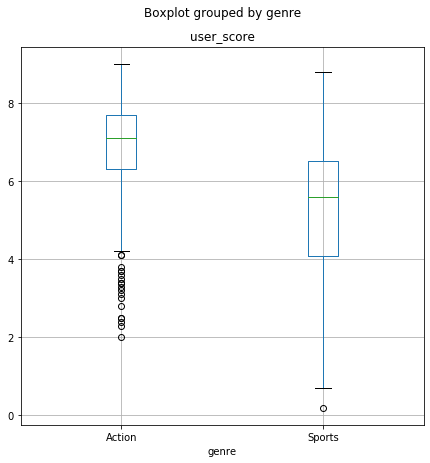

In [118]:
games_clean.query('genre == "Action" or genre == "Sports"').boxplot("user_score", by = "genre", figsize = (7, 7))
plt.show()

Мы видим, что распределение данных двух выборок отличаются. У них медианы не попадают даже в ящики друг к другу, т.к. ящики смещены. Посмотрим на числовое описание данных.

In [119]:
games_clean.query('genre == "Action"')["user_score"].describe()

count    385.000000
mean       6.807711
std        1.324565
min        2.000000
25%        6.300000
50%        7.100000
75%        7.700000
max        9.000000
Name: user_score, dtype: float64

In [120]:
games_clean.query('genre == "Sports"')["user_score"].describe()

count    156.000000
mean       5.259237
std        1.801297
min        0.200000
25%        4.075000
50%        5.600000
75%        6.525000
max        8.800000
Name: user_score, dtype: float64

Видим, что средние отличаются практически на одно среднеквадратичное отклонение. Видим отличие и в средних и в медианах.

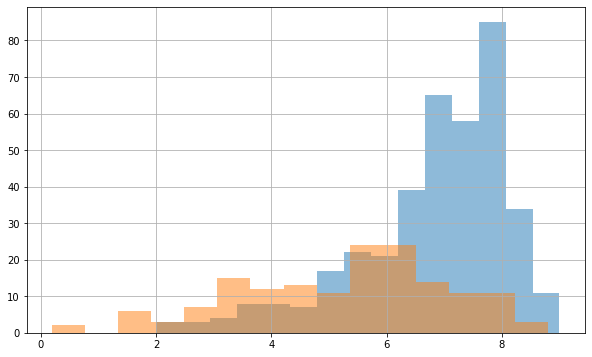

In [121]:
games_clean.query('genre == "Action"')["user_score"].hist(bins = 15, alpha = 0.5, figsize = (10, 6))
games_clean.query('genre == "Sports"')["user_score"].hist(bins = 15, alpha = 0.5)

Построим distplot, который одновременно показывает гистограмму и график плотности распределения.

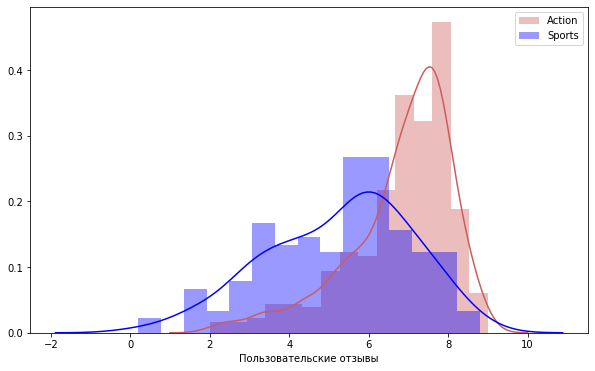

In [122]:
b = games_clean.query('genre == "Action"').dropna(axis='index', how='any', subset=['user_score']).reset_index(drop=True)
c = games_clean.query('genre == "Sports"').dropna(axis='index', how='any', subset=['user_score']).reset_index(drop=True)
plt.subplots(figsize = (10, 6))
sns.distplot(b['user_score'], bins = 15, label = "Action", color = 'indianred')
sns.distplot(c['user_score'], bins = 15, label = "Sports", color = 'blue')

plt.xlabel('Пользовательские отзывы')
plt.legend()
plt.show()

Можно убрать плотность распределения  и оставить одну гистограмму. Тогда по оси ординат появятся чистоты встречаемости.

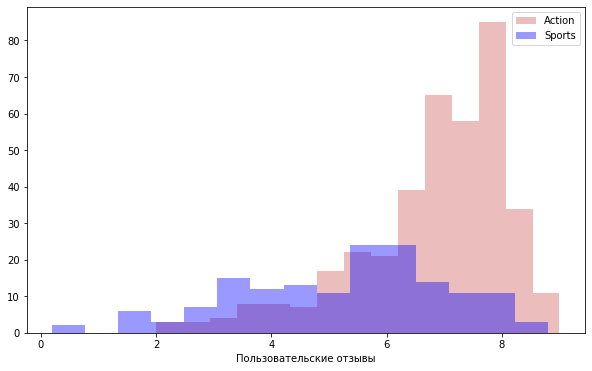

In [123]:
b = games_clean.query('genre == "Action"').dropna(axis='index', how='any', subset=['user_score']).reset_index(drop=True)
c = games_clean.query('genre == "Sports"').dropna(axis='index', how='any', subset=['user_score']).reset_index(drop=True)
plt.subplots(figsize = (10, 6))
sns.distplot(b['user_score'], bins = 15, label = "Action", color = 'indianred', kde=False)
sns.distplot(c['user_score'], bins = 15, label = "Sports", color = 'blue', kde=False)

plt.xlabel('Пользовательские отзывы')
plt.legend()
plt.show()

# 6. Выводы<a id='060'>

---

### В процессе анализа были выявлены следующие факторы, влияющие на успешность игр в 2017 году:
* Этап жизненного цикла платформы – в среднем после 5 года жизни платформы продажи ее игр идут на спад: с этой точки зрения наиболее интересными являются игры для платформ  PS4 и XOne
* Отзывы критиков на игры внутри платформы – чем лучше отзывы, тем успешнее игра (средний коэффициент корреляции 0.4)
* Жанр игры – самые популярные жанры это Action, Shooter, Sports и Role-Playing, но необходимо учитывать себестоимость производства игр разных жанров
* Регион, в котором планируется продавать игру. Поскольку портрет потенциального пользователя отличаются в различны регионах, а именно:
   - Самыми продаваемыми играми в Северной Америке являются игры на платформе XOne и PS4, в Европе - PS4, в Японии – 3DS
   - Самыми продаваемыми играми в Северной Америке и Европе являются игры жанров Action и Shooter, в Японии – Role-Playing
   - Самыми продаваемыми играми в Северной Америке и Европе являются игры с рейтингом ESRB «M» («Mature») — «Для взрослых», в Японии — «T» («Teen») — «Подросткам»
   - Для определения потенциально популярной игры и планирования рекламных кампаний необходимо учитывать вышеперечисленные факторы
   
---